# TP4 — Machine Learning 2
## Clustering, structures cachées et régimes de marché

**Question centrale :** peut-on découvrir automatiquement différents comportements de marché à partir des données seules ?

---
# PARTIE 0 — Introduction financière et géométrique

 **Concept : supervisé vs non supervisé**

| | Supervisé (TP1 à TP3) | Non supervisé (TP4) |
|---|---|---|
| Données | $(x_i, y_i)$ | $x_i$ seulement |
| Objectif | apprendre $f : X \to Y$ | découvrir une **structure** dans $X$ |
| Évaluation | erreur par rapport à la vraie réponse | pas de vraie réponse : critères internes + interprétation |

Le clustering repose sur une seule hypothèse : **deux points proches dans l'espace des features sont similaires**. Tout dépend donc de trois choix humains : **quelles features**, **quelle échelle** (normalisation) et **quelle distance**.

In [1]:
# Installation (une seule fois, puis redémarrer le kernel) : utiliser %pip dans VS Code
%pip install yfinance scikit-learn -q

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# ============================================================
# Bibliothèques générales
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# Données financières
# ============================================================
import yfinance as yf

# ============================================================
# Machine learning
# ============================================================
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.cluster import DBSCAN

# ============================================================
# Métriques
# ============================================================
from sklearn.metrics import silhouette_score

# ============================================================
# Affichage
# ============================================================
plt.rcParams["figure.figsize"] = (12, 6)

np.random.seed(42)

---
# PARTIE 1 — Construction du dataset


In [3]:
# TODO : définir le symbole financier
symbol = "BTC-USD"

In [4]:
# TODO : télécharger les données entre 2018 et 2024
data = yf.download(
    symbol,
    start="2018-01-01",
    end="2024-01-01",
    auto_adjust=False
)

# Colonnes MultiIndex (Price, Ticker) -> colonnes simples
if isinstance(data.columns, pd.MultiIndex):
    data.columns = data.columns.droplevel(1)

[*********************100%***********************]  1 of 1 completed


In [5]:
# TODO : conserver Close et Volume, puis supprimer les valeurs manquantes
data = data[["Close", "Volume"]]

data = data.dropna()

In [6]:
# TODO : afficher les premières lignes
data.head()

Price,Close,Volume
Date,,
2018-01-01,13657.200195,10291200000
2018-01-02,14982.099609,16846600192
2018-01-03,15201.000000,16871900160
2018-01-04,15599.200195,21783199744
2018-01-05,17429.500000,23840899072


---
# PARTIE 2 — Construction des features financières

 Chaque journée $i$ devient un vecteur $x_i \in \mathbb{R}^d$. Les features choisies décrivent quatre propriétés du marché :

| Feature | Formule | Propriété mesurée |
|---|---|---|
| `return` | $\frac{P_t}{P_{t-1}} - 1$ | performance du jour |
| `volatility_30d` | écart-type des rendements sur 30 jours | **risque** récent |
| `return_30d` | $\frac{P_t}{P_{t-30}} - 1$ | **performance** sur un mois (en %) |
| `momentum_30d` | $P_t - P_{t-30}$ | **tendance** sur un mois (en dollars) |
| `volume_change` | $\frac{V_t}{V_{t-1}} - 1$ | **activité** du marché |

Les fenêtres de 30 jours (≈ un mois, le Bitcoin cotant 7 jours sur 7) décrivent le **régime** de marché plutôt que le bruit d'une seule journée.

In [7]:
# TODO : dataframe de travail
df = data.copy()

In [8]:
# TODO : rendements journaliers
df["return"] = df["Close"].pct_change()

In [9]:
# TODO : volatilité glissante sur 30 jours
df["volatility_30d"] = df["return"].rolling(window=30).std()

In [10]:
# TODO : rendement sur 30 jours
df["return_30d"] = df["Close"].pct_change(30)

In [11]:
# TODO : momentum sur 30 jours (prix actuel - prix il y a 30 jours)
df["momentum_30d"] = df["Close"] - df["Close"].shift(30)

In [12]:
# TODO : variation relative du volume
df["volume_change"] = df["Volume"].pct_change()

# Sécurité : un volume nul la veille donnerait une division par zéro (infini)
df["volume_change"] = df["volume_change"].replace([np.inf, -np.inf], np.nan)

In [13]:
# TODO : supprimer les valeurs manquantes
df = df.dropna()

In [14]:
# TODO : afficher les premières lignes
print("Nombre de journées :", len(df))
df.head()

Nombre de journées : 2161


Price,Close,Volume,return,volatility_30d,return_30d,momentum_30d,volume_change
Date,,,,,,,
2018-01-31,10221.099609,8041160192,0.011359,0.064866,-0.251596,-3436.100586,-0.069080
2018-02-01,9170.540039,9959400448,-0.102783,0.064014,-0.387900,-5811.559570,0.238553
2018-02-02,8830.750000,12726899712,-0.037052,0.063907,-0.419068,-6370.250000,0.277878
2018-02-03,9174.910156,7263790080,0.038973,0.064239,-0.411835,-6424.290039,-0.429257
2018-02-04,8277.009766,7073549824,-0.097865,0.060821,-0.525115,-9152.490234,-0.026190


 Les 30 premiers jours de 2018 disparaissent : il faut 30 jours d'historique pour calculer les fenêtres. Le dataset commence donc début février 2018.

## Questions

 **Réponses**

**1. Pourquoi la volatilité glissante peut-elle être interprétée comme une mesure du risque récent ?**
Elle mesure la **dispersion des rendements journaliers sur les 30 derniers jours** : plus elle est élevée, plus les variations quotidiennes ont été amples, donc plus la perte possible d'un jour à l'autre est grande. Comme la volatilité a une mémoire (*volatility clustering*, TP2), le niveau récent est aussi une bonne estimation du risque à court terme. La fenêtre « glissante » fait que la mesure se met à jour chaque jour et reflète l'**état actuel** du marché, pas une moyenne sur 6 ans.

**2. Pourquoi le momentum peut-il contenir une information sur une tendance locale ?**
Il mesure la **variation nette du prix sur un mois** : positif, le marché est dans une phase de hausse ; négatif, dans une phase de baisse ; proche de 0, le marché stagne. Il résume la **direction** du mouvement récent, en ignorant les oscillations intermédiaires.
*Remarque :* ici le momentum est en **dollars**, donc il dépend du niveau du prix (+5 000 $ représente +100 % à 5 000 $, mais seulement +10 % à 50 000 $). `return_30d` mesure la même tendance **en pourcentage** : les deux variables sont très corrélées, et la version en pourcentage est comparable entre périodes.

**3. Pourquoi la variation du volume peut-elle refléter l'activité du marché ?**
Le volume est la quantité échangée. Une forte hausse du volume signale un **afflux d'acteurs** : réaction à une nouvelle, panique (ventes massives, liquidations de positions à effet de levier) ou euphorie spéculative. Une baisse signale un marché qui se calme ou un désintérêt. C'est un indicateur d'**intensité**, souvent associé aux journées de forte volatilité. En revanche, la variation journalière est très bruitée et ne donne pas le **sens** du mouvement.

**4. Pourquoi le clustering dépend-il fortement des features choisies ?**
Parce que l'algorithme ne voit **que** ces nombres : la similarité entre deux journées est entièrement définie par la distance entre leurs vecteurs de features. Changer les features, c'est changer la **géométrie** de l'espace, donc la notion même de « journées semblables ». Avec seulement la volatilité, on obtiendrait des groupes « calme / agité » ; avec le rendement, des groupes « haussier / baissier » ; avec le volume, des groupes selon l'activité. Ajouter une variable bruitée (comme la variation journalière de volume) peut **brouiller** les groupes, et deux variables redondantes (`return_30d` et `momentum_30d`) comptent **double** dans la distance. Il n'y a pas de clustering « objectif » : il y a un clustering **relatif à une représentation**.

---
# PARTIE 3 — Les données comme nuage de points

In [15]:
# TODO : dataframe avec return_30d et volatility_30d
features = [
    "return_30d",
    "volatility_30d"
]

X = df[features]

In [16]:
# TODO : dimension de X
X.shape

(2161, 2)

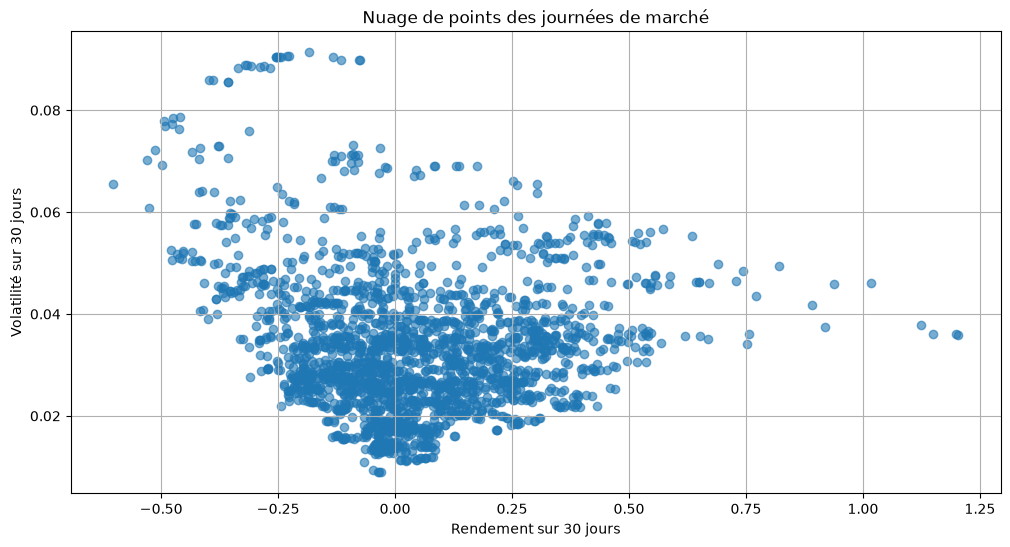

In [17]:
# Visualisation des données
plt.scatter(
    X["return_30d"],
    X["volatility_30d"],
    alpha=0.6
)

plt.title("Nuage de points des journées de marché")
plt.xlabel("Rendement sur 30 jours")
plt.ylabel("Volatilité sur 30 jours")
plt.grid(True)
plt.show()

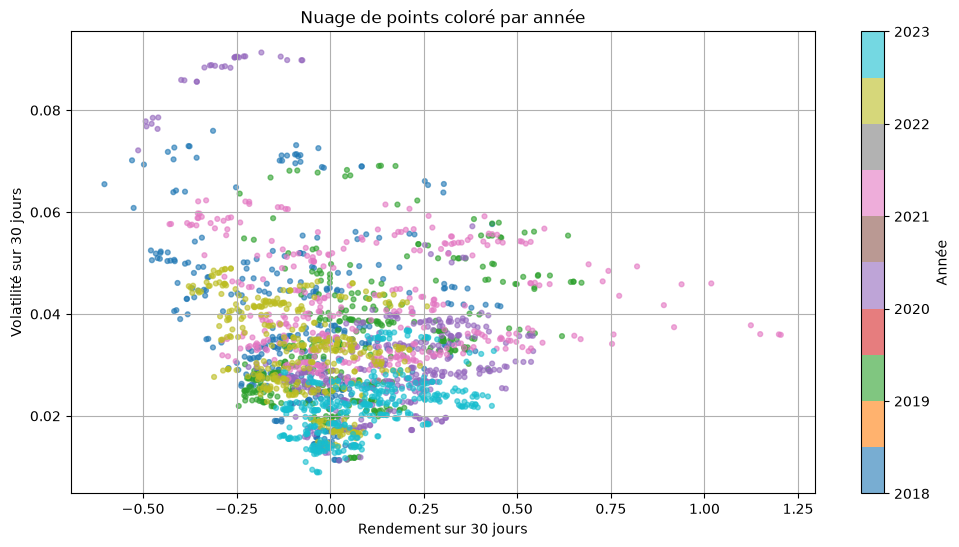

Volatilité 30 j maximale : 2020-04-06 9.1%
Rendement 30 j maximal   : 2021-01-09 +120%
Rendement 30 j minimal   : 2018-02-05 -60%


In [18]:
# Bonus : même nuage coloré par année, pour voir que les zones du nuage correspondent à des périodes
sc = plt.scatter(X["return_30d"], X["volatility_30d"], c=df.index.year, cmap="tab10", alpha=0.6, s=12)
plt.colorbar(sc, label="Année")
plt.title("Nuage de points coloré par année")
plt.xlabel("Rendement sur 30 jours"); plt.ylabel("Volatilité sur 30 jours"); plt.grid(True)
plt.show()

# Les journées les plus éloignées du centre du nuage
print("Volatilité 30 j maximale :", df["volatility_30d"].idxmax().date(), f"{df['volatility_30d'].max():.1%}")
print("Rendement 30 j maximal   :", df["return_30d"].idxmax().date(), f"{df['return_30d'].max():+.0%}")
print("Rendement 30 j minimal   :", df["return_30d"].idxmin().date(), f"{df['return_30d'].min():+.0%}")

## Questions

 **Réponses** (à confirmer avec ton graphique)

**1. Certaines régions semblent-elles plus denses que d'autres ?**
Oui. La grande majorité des journées forme un **noyau dense** autour d'un rendement sur 30 jours proche de 0 (entre −20 % et +20 %) et d'une volatilité modérée (environ 2 à 4 % par jour). Plus on s'éloigne de ce noyau (rendements mensuels extrêmes, volatilité très élevée), plus les points sont **rares et dispersés**.

**2. Observe-t-on des groupes potentiels ?**
Pas de groupes nettement séparés par des zones vides : le nuage est plutôt **continu**, en forme d'éventail ou d'entonnoir (plus la volatilité est élevée, plus les rendements sur 30 jours sont dispersés, vers le haut comme vers le bas). On devine cependant des **zones** : une zone calme (volatilité basse, rendements faibles), une branche de forte hausse (fin 2020 - début 2021) et une zone de forte volatilité avec rendements négatifs (krachs). Ce sont des régions de densité différente plutôt que des « îlots » séparés, ce qui annonce que tout découpage aura une part d'arbitraire.

**3. Pourquoi certaines périodes semblent-elles éloignées du reste des données ?**
Parce qu'elles correspondent à des **événements exceptionnels** : le krach de mars 2020 (volatilité record), la bulle de fin 2020 - début 2021 (rendements sur 30 jours supérieurs à +50 %), les krachs de 2018 et de mai-juin 2022 (rendements sur 30 jours de −30 à −50 %). Ces journées sont rares et extrêmes, donc loin du comportement « habituel ». Comme les features sont calculées sur 30 jours glissants, une même crise produit une **traînée** de points consécutifs, d'où les filaments que l'on voit dans le nuage.

**4. Pourquoi peut-on dire que le clustering repose d'abord sur une intuition géométrique ?**
Parce qu'il traduit une question financière (« quelles journées se ressemblent ? ») en une question de **géométrie** : quels points sont **proches** dans l'espace ? Les journées deviennent des points, la similarité devient une **distance**, et un cluster devient une **région** de l'espace (un groupe compact pour K-Means, une zone dense pour DBSCAN). L'algorithme ne « comprend » rien à la finance : il découpe un nuage de points. C'est nous qui donnons ensuite un sens économique aux régions trouvées.

---
# PARTIE 4 — Importance de la normalisation

 **Concept** : K-Means et DBSCAN utilisent la distance euclidienne $d(x, y) = \sqrt{\sum_j (x_j - y_j)^2}$. Chaque variable contribue par $(x_j - y_j)^2$ : une variable dont les écarts se comptent en **milliers** écrase une variable dont les écarts se comptent en **centièmes**.

In [19]:
# TODO : matrice avec les 4 features
features = [
    "return_30d",
    "volatility_30d",
    "momentum_30d",
    "volume_change"
]

X = df[features]

In [20]:
# TODO : statistiques descriptives
X.describe()

Price,return_30d,volatility_30d,momentum_30d,volume_change
count,2161.000000,2161.000000,2161.000000,2161.000000
mean,0.039726,0.033382,409.455691,0.036263
std,0.220967,0.013575,5496.852660,0.308875
min,-0.603168,0.008887,-25243.070312,-0.869188
25%,-0.106966,0.024538,-1653.292969,-0.126952
50%,0.011190,0.031403,121.052734,-0.008205
75%,0.174495,0.039732,2357.527344,0.147373
max,1.203918,0.091330,25273.820312,5.439003


## Questions

 **Réponses**

**1. Les variables semblent-elles avoir des échelles comparables ?**
Non, pas du tout. `return_30d` varie typiquement entre −0,5 et +1, `volatility_30d` entre environ 0,01 et 0,1, `volume_change` est surtout entre −0,5 et quelques unités, alors que `momentum_30d` (en dollars) varie de **−20 000 à +20 000** environ, avec un écart-type de plusieurs milliers.

**2. Quelle variable semble posséder les valeurs les plus grandes ?**
`momentum_30d`, de très loin : son écart-type est environ **100 000 fois** plus grand que celui de la volatilité. C'est la seule variable exprimée en dollars, et elle dépend du niveau du prix du Bitcoin.

**3. Pourquoi cela peut-il devenir problématique pour le calcul des distances ?**
Dans la somme $\sum_j (x_j - y_j)^2$, un écart de momentum de 1 000 $ ajoute $10^6$, alors qu'un écart de volatilité de 5 points (énorme : une journée calme contre une journée de crise) ajoute $0{,}05^2 = 0{,}0025$. La distance entre deux journées est donc **presque égale à l'écart de momentum**. Les autres variables n'ont plus aucune influence : l'algorithme ignore le risque, le rendement en pourcentage et le volume.

**4. Que se passerait-il si une seule variable dominait toutes les distances ?**
Le clustering serait en pratique un **découpage unidimensionnel** de cette variable : K-Means couperait simplement le momentum en tranches (forte baisse en $, stagnation, forte hausse en $). Pire, comme le momentum en dollars est grand surtout quand le prix est élevé, les clusters refléteraient surtout le **niveau de prix** (2021 contre 2018-2019) et non le comportement du marché. Le résultat serait trompeur : on croirait détecter des régimes alors qu'on ne fait que trier une variable selon son unité de mesure. C'est ce qu'on vérifie à la partie 12.

In [21]:
# TODO : construire un StandardScaler
scaler = StandardScaler()

In [22]:
# TODO : normaliser les données
X_scaled = scaler.fit_transform(X)

In [23]:
# TODO : transformer X_scaled en DataFrame
X_scaled = pd.DataFrame(
    X_scaled,
    columns=features,
    index=X.index
)

X_scaled.head()

,return_30d,volatility_30d,momentum_30d,volume_change
Date,,,,
2018-01-31,-1.318703,2.319933,-0.699754,-0.341133
2018-02-01,-1.935699,2.257138,-1.132003,0.655075
2018-02-02,-2.076783,2.249283,-1.233665,0.782423
2018-02-03,-2.044041,2.273746,-1.243498,-1.507499
2018-02-04,-2.556817,2.021875,-1.739934,-0.202244


In [24]:
# TODO : statistiques descriptives des données normalisées
X_scaled.describe().round(3)

,return_30d,volatility_30d,momentum_30d,volume_change
count,2161.000,2161.000,2161.000,2161.000
mean,-0.000,0.000,-0.000,-0.000
std,1.000,1.000,1.000,1.000
min,-2.910,-1.805,-4.668,-2.932
25%,-0.664,-0.652,-0.375,-0.529
50%,-0.129,-0.146,-0.052,-0.144
75%,0.610,0.468,0.354,0.360
max,5.270,4.270,4.524,17.496


 **Pourquoi `fit_transform` sur tout le dataset, alors qu'au TP3 on ajustait le scaler sur le train uniquement ?** Ici il n'y a **ni cible ni jeu de test** : on n'évalue pas une prévision, on décrit la structure de l'ensemble des données. Il n'y a donc pas de fuite d'information possible. (Si on voulait ensuite classer de nouvelles journées en temps réel, il faudrait ajuster le scaler et K-Means sur le passé seulement.)

## Questions

 **Réponses**

**1. Les variables semblent-elles maintenant comparables ?**
Oui : elles sont toutes exprimées en **nombre d'écarts-types** par rapport à leur moyenne. Une valeur de +2 signifie « deux écarts-types au-dessus de la moyenne », quelle que soit la variable. Elles pèsent donc à égalité dans les distances.

**2. Les moyennes sont-elles proches de zéro ? Pourquoi ?**
Oui (de l'ordre de $10^{-17}$, c'est-à-dire 0 aux erreurs d'arrondi près). Le `StandardScaler` calcule $z = \frac{x - \mu}{\sigma}$ : en soustrayant à chaque variable sa propre moyenne $\mu$, on la **centre** sur 0 par construction.

**3. Les écarts-types sont-ils proches de 1 ? Pourquoi ?**
Oui (1,000 environ ; `describe` affiche 1,0002 car pandas divise par $n-1$ alors que le scaler divise par $n$). En divisant par l'écart-type $\sigma$, on **réduit** chaque variable à une dispersion unitaire.

À noter : la normalisation change l'échelle mais **pas la forme** des distributions. `volume_change` garde ses valeurs extrêmes, qui deviennent des valeurs à 10 ou 20 écarts-types (voir le `max`) ; ces points restent très éloignés des autres.

**4. Pourquoi la normalisation est-elle presque toujours nécessaire en clustering ?**
Parce que les algorithmes de clustering sont entièrement fondés sur des **distances**, et qu'une distance n'a de sens que si les variables sont sur des échelles comparables. Sans normalisation, le résultat dépend des **unités** choisies (dollars, pourcentages, milliers…), ce qui est arbitraire : changer d'unité changerait les clusters. La normalisation donne à chaque variable un poids comparable (par défaut, égal), de sorte que le regroupement reflète la structure des données et non les unités de mesure.

---
# PARTIE 5 — K-Means

 **Concept** : K-Means cherche $K$ centres $\mu_1, \dots, \mu_K$ qui minimisent l'**inertie** :
$$\text{Inertie} = \sum_{i=1}^{n} \| x_i - \mu_{c(i)} \|^2$$
(la somme des distances au carré entre chaque point et le centre de son cluster). L'algorithme alterne deux étapes jusqu'à stabilisation : **(1)** affecter chaque point au centre le plus proche ; **(2)** recalculer chaque centre comme la **moyenne** de ses points.

In [25]:
# TODO : modèle K-Means à 3 clusters
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10        # 10 initialisations différentes, on garde la meilleure (évite un mauvais minimum local)
)

In [26]:
# TODO : entraîner et récupérer les labels
labels = kmeans.fit_predict(X_scaled)

In [27]:
# TODO : ajouter les labels au dataframe
df["cluster"] = labels

In [28]:
# TODO : afficher return_30d, volatility_30d, cluster
df[["return_30d", "volatility_30d", "cluster"]].head(10)

Price,return_30d,volatility_30d,cluster
Date,,,
2018-01-31,-0.251596,0.064866,2
2018-02-01,-0.387900,0.064014,2
2018-02-02,-0.419068,0.063907,2
2018-02-03,-0.411835,0.064239,2
2018-02-04,-0.525115,0.060821,2
2018-02-05,-0.603168,0.065481,2
2018-02-06,-0.529422,0.070166,2
2018-02-07,-0.497610,0.069337,2
2018-02-08,-0.433685,0.071823,2


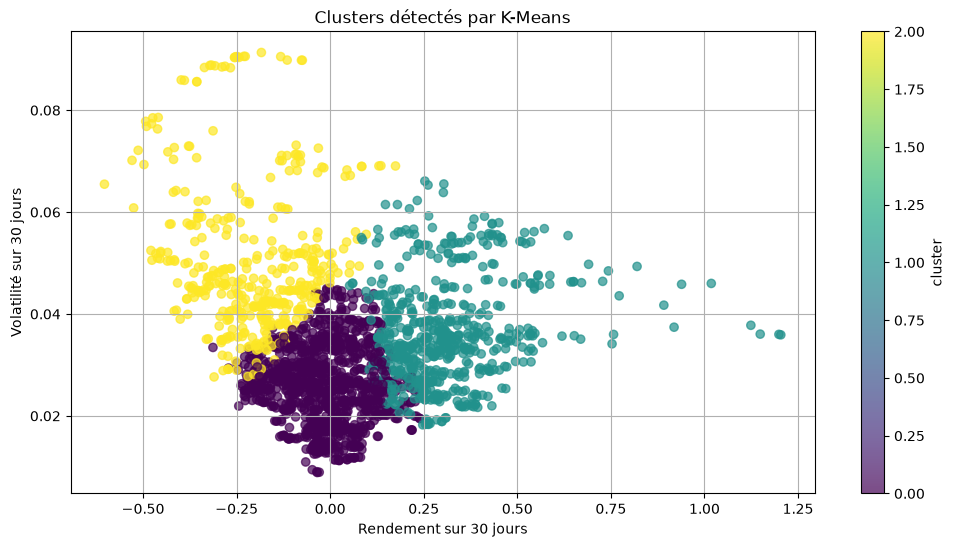

In [29]:
# Visualisation des clusters K-Means
plt.scatter(
    df["return_30d"],
    df["volatility_30d"],
    c=df["cluster"],
    cmap="viridis",
    alpha=0.7
)

plt.title("Clusters détectés par K-Means")
plt.xlabel("Rendement sur 30 jours")
plt.ylabel("Volatilité sur 30 jours")
plt.grid(True)
plt.colorbar(label="cluster")
plt.show()

 **Attention à la lecture** : K-Means a travaillé dans un espace à **4 dimensions** (normalisé), alors que le graphique n'en montre que **2** (non normalisées). Deux points qui semblent proches sur le graphique peuvent être éloignés en `momentum_30d` ou en `volume_change` : c'est pourquoi les couleurs peuvent se **chevaucher** à l'écran sans que l'algorithme ait « fait une erreur ».

## Questions

 **Réponses** (à adapter à ton graphique)

**1. Les clusters semblent-ils relativement compacts ?**
Partiellement. Le groupe correspondant au **noyau calme** (rendement proche de 0, volatilité modérée) est compact et contient la majorité des journées. Les autres groupes, qui rassemblent les journées **extrêmes** (forte hausse, ou forte volatilité / forte baisse), sont beaucoup plus **étalés**, car les points rares et éloignés sont dispersés. K-Means, qui affecte **tous** les points à un cluster, doit bien les ranger quelque part.

**2. Certaines zones semblent-elles ambiguës ?**
Oui : aux **frontières** entre les groupes, les points ont des caractéristiques intermédiaires (par exemple un rendement de +25 % avec une volatilité moyenne). Comme le nuage est continu, la frontière est une coupure **nette mais arbitraire** au milieu d'une zone où les points sont presque identiques. Deux journées très semblables peuvent ainsi recevoir des labels différents. Les chevauchements de couleurs dans la projection 2D viennent aussi des deux variables non affichées.

**3. Observe-t-on des régions plus denses que d'autres ?**
Oui : le cœur du nuage (journées « normales ») est très dense ; les régions extrêmes (krachs, bulles) sont peu denses. K-Means ne tient **pas compte** de la densité : il cherche des groupes compacts autour de centres, ce qui l'amène souvent à couper le noyau dense en morceaux, ou à créer des clusters étalés pour les points rares.

**4. Pourquoi K-Means tend-il à produire des clusters relativement sphériques ?**
Parce que chaque point est affecté au **centre le plus proche** au sens de la distance euclidienne : la frontière entre deux clusters est la médiatrice entre leurs centres (un hyperplan), et chaque cluster est une **cellule de Voronoï** convexe. L'inertie pénalise les distances au carré au centre de façon **identique dans toutes les directions** : K-Means suppose implicitement des groupes ronds, de taille et de dispersion comparables. Il ne peut pas représenter des groupes allongés, courbes, emboîtés ou de densités très différentes.

In [30]:
# TODO : coordonnées des centroïdes
centers = kmeans.cluster_centers_

centers

array([[-0.24979071, -0.55284282, -0.14267818,  0.02321346],
       [ 1.23342609,  0.21854162,  1.03263707, -0.00252966],
       [-1.10853243,  1.25167456, -1.11727496, -0.06236329]])

In [31]:
# TODO : centroïdes en DataFrame
centers_df = pd.DataFrame(
    centers,
    columns=features
)

centers_df

,return_30d,volatility_30d,momentum_30d,volume_change
0,-0.249791,-0.552843,-0.142678,0.023213
1,1.233426,0.218542,1.032637,-0.002530
2,-1.108532,1.251675,-1.117275,-0.062363


In [32]:
# Bonus : centroïdes ramenés dans les unités d'origine (plus lisible financièrement)
centers_original = pd.DataFrame(
    scaler.inverse_transform(centers),
    columns=features
)
centers_original.round(3)

,return_30d,volatility_30d,momentum_30d,volume_change
0,-0.015,0.026,-374.644,0.043
1,0.312,0.036,6084.396,0.035
2,-0.205,0.050,-5730.619,0.017


## Questions

 **Réponses**

**1. Que représente un centroïde dans K-Means ?**
C'est le **centre de gravité** d'un cluster : le vecteur moyen des journées qui le composent, dans l'espace normalisé. Chaque coordonnée indique de combien d'écarts-types ce groupe s'écarte de la moyenne générale sur une variable. C'est aussi le point de référence utilisé pour affecter les journées : une journée appartient au cluster dont le centroïde est le plus proche.

**2. Certains centroïdes semblent-ils correspondre à des marchés plus volatils ?**
Oui : l'un des centroïdes a une coordonnée `volatility_30d` nettement **positive** (par exemple +1 à +2 écarts-types, soit une volatilité de l'ordre de 5-6 % par jour en unités d'origine), souvent associée à un `return_30d` négatif. Il correspond aux périodes de crise. Le centroïde du groupe « calme » a au contraire une volatilité **négative** (sous la moyenne).

**3. Pourquoi un centroïde peut-il être vu comme un comportement moyen ?**
Parce qu'il est littéralement la **moyenne** des journées du cluster : il résume le groupe par un profil type (« rendement mensuel de −20 %, volatilité de 5 % par jour, momentum négatif »). C'est le « portrait-robot » du régime de marché correspondant, utile pour l'interpréter.

**4. Pourquoi les centroïdes ne correspondent-ils pas nécessairement à des journées réelles ?**
Une moyenne n'est généralement **égale à aucune** des valeurs moyennées : la moyenne de 1 et 3 est 2, qui n'est ni 1 ni 3. Le centroïde est un point **calculé**, qui peut tomber dans une zone vide de l'espace. C'est encore plus vrai pour des groupes dispersés ou de forme irrégulière, et quand des valeurs extrêmes tirent la moyenne. C'est la différence avec **K-Medoids**, où chaque centre est obligatoirement une observation réelle.

---
# PARTIE 6 — Choix du nombre de clusters

In [33]:
# TODO : inerties pour K entre 1 et 10
inertias = []

K_values = range(1, 11)

for k in K_values:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    inertias.append(model.inertia_)

In [34]:
# TODO : afficher les inerties
for k, inertia in zip(K_values, inertias):
    print("K =", k, "| inertie =", round(inertia, 1))

K = 1 | inertie = 8644.0
K = 2 | inertie = 6379.3
K = 3 | inertie = 4972.4
K = 4 | inertie = 4183.9
K = 5 | inertie = 3755.0
K = 6 | inertie = 3395.9
K = 7 | inertie = 3085.8
K = 8 | inertie = 2777.4
K = 9 | inertie = 2617.8
K = 10 | inertie = 2401.1


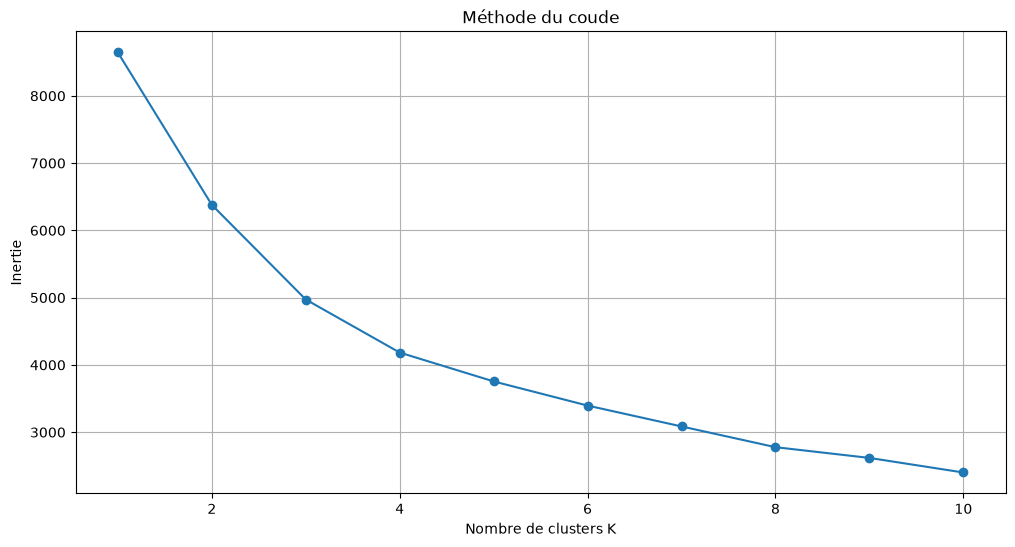

In [35]:
# Visualisation de la méthode du coude
plt.plot(
    K_values,
    inertias,
    marker="o"
)

plt.title("Méthode du coude")
plt.xlabel("Nombre de clusters K")
plt.ylabel("Inertie")
plt.grid(True)
plt.show()

## Questions

 **Réponses**

**1. Pourquoi l'inertie diminue-t-elle lorsque K augmente ?**
Avec plus de centres, chaque point a plus de chances d'en avoir un **près de lui** : la distance au centre le plus proche ne peut que diminuer (au pire, ajouter un centre ne change rien). Avec $K = 1$, l'inertie est la dispersion totale des données (ici ≈ $n \times 4$, car chaque variable normalisée a une variance de 1) ; avec $K = n$, chaque point est son propre centre et l'inertie vaut **0**. L'inertie ne peut donc pas servir seule à choisir K : elle favorise toujours le plus grand K.

**2. Observez-vous un éventuel « coude » ?**
On cherche le K à partir duquel la courbe s'aplatit : avant, ajouter un cluster réduit fortement l'inertie ; après, le gain devient faible. Sur ces données, le coude est en général **peu marqué**, situé vers **K = 3 ou 4** : la courbe décroît de façon assez régulière. C'est cohérent avec un nuage **continu**, sans groupes nettement séparés (partie 3).

**3. Pourquoi choisir un très grand nombre de clusters peut-il devenir dangereux ?**
- On **sur-découpe** les données : des groupes de quelques journées, qui ne représentent plus de vrais régimes mais du **bruit** ou des épisodes uniques. C'est l'équivalent du surapprentissage en supervisé.
- Les clusters deviennent **instables** (changer légèrement les données ou l'initialisation change le découpage) et **impossibles à interpréter** : on ne sait pas donner un sens financier à 10 régimes.
- On perd l'objectif du clustering, qui est de **résumer** les données en quelques comportements types.

**4. Pourquoi le choix de K reste-t-il partiellement subjectif ?**
Parce qu'il n'y a **pas de vraie réponse** à laquelle se comparer (pas de cible). Le coude est souvent flou et son repérage se fait « à l'œil » ; les critères numériques (inertie, silhouette) ne sont pas toujours d'accord entre eux ; et le « bon » nombre de régimes dépend de l'**objectif** : 2 régimes (calme / stress) pour un gestionnaire de risque, 4 ou 5 pour une analyse plus fine. Les données peuvent aussi contenir **plusieurs structures** à différentes échelles.

In [36]:
# TODO : score de silhouette pour K entre 2 et 10
silhouette_scores = []

K_values_silhouette = range(2, 11)

for k in K_values_silhouette:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels_k = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels_k)

    silhouette_scores.append(score)

In [37]:
# Affichage des scores de silhouette
for k, score in zip(K_values_silhouette, silhouette_scores):
    print("K =", k, " | Score de silhouette =", score)

K = 2  | Score de silhouette = 0.2770369927014068
K = 3  | Score de silhouette = 0.287227478271164
K = 4  | Score de silhouette = 0.2902586773743709
K = 5  | Score de silhouette = 0.2689053050220768
K = 6  | Score de silhouette = 0.2753129184556351
K = 7  | Score de silhouette = 0.25687579533213784
K = 8  | Score de silhouette = 0.260210746589843
K = 9  | Score de silhouette = 0.2496744061426879
K = 10  | Score de silhouette = 0.2319022808912693


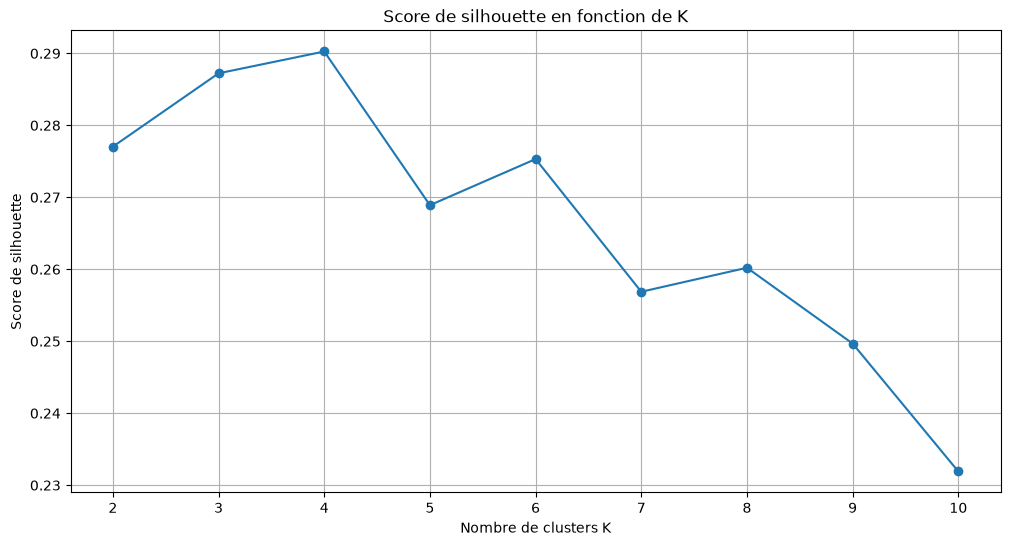

In [38]:
# Visualisation du score de silhouette
plt.plot(
    K_values_silhouette,
    silhouette_scores,
    marker="o"
)

plt.title("Score de silhouette en fonction de K")
plt.xlabel("Nombre de clusters K")
plt.ylabel("Score de silhouette")
plt.grid(True)
plt.show()

 **Le score de silhouette** : pour chaque point $i$, on calcule $a(i)$, la distance moyenne aux points de **son** cluster, et $b(i)$, la distance moyenne aux points du cluster **voisin le plus proche**. Alors $s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))} \in [-1, 1]$ :
- proche de **1** : le point est bien au centre de son groupe et loin des autres ;
- proche de **0** : il est à la frontière entre deux groupes ;
- **négatif** : il serait mieux dans un autre cluster.

Le score global est la moyenne sur tous les points. Il récompense à la fois la **compacité** et la **séparation**, contrairement à l'inertie.

## Questions

 **Réponses** (à adapter à tes valeurs)

**1. Pour quelle valeur de K le score de silhouette semble-t-il le plus élevé ?**
Lis la valeur maximale dans ton tableau. Sur ce type de données, le meilleur score est souvent obtenu pour un **petit K (2 ou 3)**, avec des valeurs **modestes** (de l'ordre de 0,3 à 0,5). Un score maximal pour K = 2 signifie souvent que l'algorithme isole simplement un petit groupe de journées extrêmes du reste.

**2. Ce résultat est-il cohérent avec la méthode du coude ?**
En général **à peu près** : les deux méthodes pointent vers un petit nombre de clusters (2 à 4). Mais elles ne donnent pas toujours exactement le même K, car elles ne mesurent pas la même chose : l'inertie mesure seulement la **compacité**, la silhouette mesure la compacité **et la séparation**. Leur désaccord confirme que la structure n'est pas nette.

Un score de silhouette **modéré** (nettement inférieur à 0,7) indique que les groupes **ne sont pas bien séparés** : c'est cohérent avec un nuage continu. K-Means découpe ces données en régions, mais il n'y a pas de « vrais » groupes isolés.

**3. Pourquoi un score numérique ne suffit-il pas toujours à choisir le meilleur clustering ?**
- Chaque score repose sur une **hypothèse** sur ce qu'est un « bon » cluster : la silhouette favorise les groupes compacts et ronds, comme K-Means. Elle est mal adaptée à des groupes de forme allongée ou de densités différentes.
- Un score élevé peut correspondre à un découpage **sans intérêt** : isoler 20 journées extrêmes du reste donne une bonne silhouette, mais ne décrit pas les régimes de marché.
- Les écarts de score entre deux valeurs de K sont souvent **faibles** et instables.
- Le score dépend entièrement des **features et de la normalisation** choisies : il juge la qualité du découpage dans une représentation donnée, pas la pertinence de cette représentation.

**4. Pourquoi l'interprétation métier reste-t-elle indispensable ?**
Parce que l'objectif n'est pas d'optimiser un score mais de trouver des groupes **utiles et cohérents** : est-ce que les clusters correspondent à des régimes financiers identifiables (calme, haussier, crise) ? Apparaissent-ils par **périodes** cohérentes dans le temps (partie 8) ? Sont-ils **stables** ? Peut-on les utiliser pour une décision (gestion du risque, allocation) ? Seule une personne qui connaît le domaine peut juger si un découpage a un **sens**. Un clustering mathématiquement optimal mais financièrement absurde est inutile.

---
# PARTIE 7 — Interprétation financière des clusters

In [39]:
# TODO : nombre d'observations par cluster
counts = df["cluster"].value_counts().sort_index()
print(counts.to_string())

# Vérification : un cluster minuscule signale un cluster "d'aberrations"
if counts.min() < 0.02 * len(df):
    print("\n⚠️ Le cluster", counts.idxmin(), "ne contient que", counts.min(), "jour(s) : voir la remarque ci-dessous.")

cluster
0    1158
1     597
2     406


 **Si un cluster ne contient que quelques jours** : c'est presque toujours dû à `volume_change`. Quelques journées ont une variation de volume énorme (par exemple +300 % ou plus), soit 10 à 20 écarts-types après normalisation. K-Means minimise des distances **au carré** : il préfère « dépenser » un centroïde entier pour ces quelques points extrêmes plutôt que de les laisser déformer les autres groupes. Ce n'est pas un bug, c'est une **leçon** : K-Means est très sensible aux valeurs aberrantes. Dans ce cas, le nommage automatique de la partie suivante appellera ce mini-cluster « volatil » ; renomme-le plutôt **« Journées atypiques (pic de volume) »**, et note-le dans tes réponses. Pour éviter ce phénomène, on pourrait borner `volume_change` (par exemple avec `.clip(-1, 3)`) ou utiliser un `RobustScaler`.

In [40]:
# TODO : moyennes par cluster
cluster_summary = df.groupby("cluster")[features].mean()

cluster_summary

Price,return_30d,volatility_30d,momentum_30d,volume_change
cluster,,,,
0,-0.015142,0.025884,-369.092785,0.043369
1,0.312696,0.036373,6095.267188,0.035578
2,-0.205166,0.050369,-5730.619012,0.017005


In [41]:
# TODO : médianes par cluster
cluster_median = df.groupby("cluster")[features].median()

cluster_median

Price,return_30d,volatility_30d,momentum_30d,volume_change
cluster,,,,
0,-0.013125,0.026029,-144.344971,-0.005181
1,0.285835,0.035009,4757.296875,-0.004692
2,-0.198253,0.046254,-3829.268555,-0.029234


In [42]:
# Bonus : tableau plus lisible (pourcentages) + période typique de chaque cluster
lisible = pd.DataFrame({
    "nb_jours": df["cluster"].value_counts().sort_index(),
    "rendement_30j_median": cluster_median["return_30d"].map("{:+.1%}".format),
    "volatilité_30j_médiane": cluster_median["volatility_30d"].map("{:.2%}".format),
    "rendement_jour_moyen": df.groupby("cluster")["return"].mean().map("{:+.2%}".format),
    "années_les_plus_fréquentes": df.groupby("cluster").apply(
        lambda g: ", ".join(str(a) for a in g.index.year.value_counts().index[:2])
    ),
})
lisible

,nb_jours,rendement_30j_median,volatilité_30j_médiane,rendement_jour_moyen,années_les_plus_fréquentes
cluster,,,,,
0,1158,-1.3%,2.60%,-0.05%,"2023, 2019"
1,597,+28.6%,3.50%,+0.85%,"2021, 2020"
2,406,-19.8%,4.63%,-0.39%,"2022, 2021"


## Questions

 **Réponses** (à adapter : retrouve chaque cluster par ses caractéristiques dans tes tableaux)

**1. Quel cluster semble correspondre aux périodes les plus volatiles ?**
Celui dont la **volatilité_30d moyenne et médiane** est la plus élevée (souvent autour de 5-6 % par jour, contre 2-3 % pour les autres). C'est en général aussi le cluster le **moins nombreux**, avec beaucoup de journées en 2018, mars-avril 2020 et 2021-2022.

**2. Quel cluster semble correspondre aux périodes de rendement positif ?**
Celui dont le **return_30d** moyen et médian est le plus élevé (souvent entre +30 % et +60 % sur 30 jours), avec un `momentum_30d` fortement positif. Il regroupe surtout les phases de **bulle** : fin 2020 - début 2021, et des épisodes de 2019 et 2023.

**3. Quel cluster semble correspondre aux périodes de rendement négatif ?**
Celui dont le return_30d médian est **négatif**. Selon le découpage obtenu, ce peut être le cluster le plus volatil (les baisses du Bitcoin s'accompagnent souvent d'une forte volatilité : krachs de 2018, de mars 2020, de mai-juin 2022) ou un cluster « baisse lente » à volatilité moyenne. Avec seulement 3 clusters, il est fréquent qu'il n'y ait **pas** de cluster purement baissier : le cluster majoritaire contient à la fois des mois légèrement positifs et légèrement négatifs.

**4. Pourquoi est-il utile de comparer moyenne et médiane ?**
La moyenne est **sensible aux valeurs extrêmes** ; la médiane (la valeur du milieu) ne l'est pas. Si les deux sont proches, le cluster est homogène. Si elles diffèrent beaucoup, quelques journées extrêmes **tirent la moyenne** et le cluster est hétérogène. C'est typiquement le cas de `volume_change` (quelques pics de +300 % gonflent la moyenne alors que la médiane est proche de 0) et du cluster des journées extrêmes. Pour décrire un comportement « typique », la médiane est plus fiable. Comme K-Means calcule ses centres avec des **moyennes**, il est lui-même sensible aux extrêmes.

**5. Peut-on donner un nom financier à chaque cluster ?**
Oui, approximativement, à partir des profils : par exemple « marché calme / neutre » (volatilité basse, rendement proche de 0, majorité des jours), « marché haussier / euphorie » (forte hausse sur 30 jours), « marché volatil / crise » (volatilité élevée, rendement souvent négatif). Mais ces noms sont des **simplifications** : chaque cluster contient aussi des journées qui ne correspondent pas à son nom. La cellule suivante propose des noms à partir des statistiques, que tu dois **vérifier** et ajuster.

In [43]:
# TODO : interprétation des clusters
# Les numéros (0, 1, 2) sont arbitraires : on choisit les noms à partir des statistiques.
# Règle utilisée ici (à vérifier sur tes tableaux) :
#   - le cluster à la volatilité médiane la plus élevée          -> "Marché volatil (crise)"
#   - parmi les autres, celui au rendement 30 j médian le plus haut -> "Marché haussier"
#   - le dernier                                                  -> "Marché calme"
vol_order = cluster_median["volatility_30d"].sort_values(ascending=False).index
volatile = vol_order[0]
others = cluster_median.drop(index=volatile)
bullish = others["return_30d"].idxmax()
calm = others.drop(index=bullish).index[0]

cluster_names = {
    volatile: "Marché volatil (crise)",
    bullish: "Marché haussier",
    calm: "Marché calme",
}
print(cluster_names)

# Tu peux aussi écrire le dictionnaire à la main après avoir observé tes tableaux, par exemple :
# cluster_names = {0: "Marché calme", 1: "Marché volatil (crise)", 2: "Marché haussier"}

df["cluster_name"] = df["cluster"].map(cluster_names)

df[["return_30d", "volatility_30d", "cluster", "cluster_name"]].head()

{np.int32(2): 'Marché volatil (crise)', np.int32(1): 'Marché haussier', np.int32(0): 'Marché calme'}


Price,return_30d,volatility_30d,cluster,cluster_name
Date,,,,
2018-01-31,-0.251596,0.064866,2,Marché volatil (crise)
2018-02-01,-0.387900,0.064014,2,Marché volatil (crise)
2018-02-02,-0.419068,0.063907,2,Marché volatil (crise)
2018-02-03,-0.411835,0.064239,2,Marché volatil (crise)
2018-02-04,-0.525115,0.060821,2,Marché volatil (crise)


## Questions

 **Réponses**

**1. Les noms donnés aux clusters sont-ils évidents ou discutables ?**
**Discutables.** Ils résument une tendance **moyenne**, mais chaque cluster est hétérogène : le « marché calme » contient des mois de baisse modérée, le « marché volatil » peut contenir à la fois des krachs et des envolées (la volatilité est forte dans les deux cas), et les journées proches des frontières pourraient recevoir l'autre nom. Par ailleurs, la règle de nommage dépend des variables regardées : en se focalisant sur le volume, on choisirait d'autres noms.

**2. Deux étudiants pourraient-ils proposer des noms différents ?**
Oui. L'un pourrait appeler un cluster « crise » parce que sa volatilité est forte, l'autre « marché spéculatif » parce qu'il y voit surtout des journées de 2021 ; l'un pourrait insister sur le rendement (« haussier / baissier »), l'autre sur le risque (« calme / agité »). Les deux lectures peuvent être défendues à partir des mêmes chiffres. De plus, avec un autre `random_state`, d'autres features ou un autre K, les clusters eux-mêmes changeraient.

**3. Pourquoi cela montre-t-il que le clustering nécessite une interprétation humaine ?**
L'algorithme ne produit que des **numéros** : il dit « ces journées se ressemblent », jamais **pourquoi** ni **ce que cela signifie**. Le passage de « cluster 2 » à « marché en crise » est un **acte d'interprétation**, fondé sur des connaissances financières (savoir que mars 2020 est un krach, qu'une volatilité de 6 % par jour est exceptionnelle). Sans cette étape, le résultat est inutilisable ; avec elle, il dépend de la personne qui interprète.

**4. Pourquoi faut-il rester prudent avant d'utiliser ces clusters pour prendre une décision financière ?**
- Les clusters sont calculés sur **toute la période** (2018-2023), y compris le futur de chaque journée : la normalisation et les centres utilisent des données qu'on n'aurait pas eues en temps réel. On reconnaît une crise **après coup**, pas pendant.
- Les features sur 30 jours sont **en retard** : un cluster « crise » est détecté quand la crise a déjà eu lieu.
- Le découpage dépend de choix **arbitraires** (features, normalisation, K, algorithme) et peut être **instable**.
- Un cluster décrit le **passé** ; rien ne garantit que le comportement suivant sera le même (appartenir au cluster « haussier » ne veut pas dire que la hausse va continuer).
- Il faudrait tester leur valeur **hors échantillon** (en recalculant les clusters uniquement sur le passé) avant toute utilisation réelle.

---
# PARTIE 8 — Visualiser les clusters dans le temps

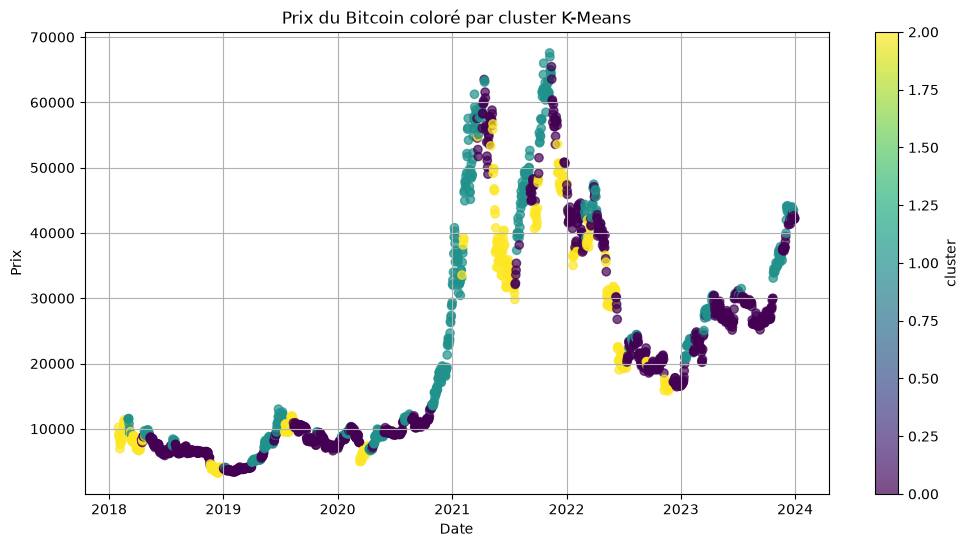

In [44]:
# Visualisation du prix du Bitcoin avec coloration par cluster
plt.scatter(
    df.index,
    df["Close"],
    c=df["cluster"],
    cmap="viridis",
    alpha=0.7
)

plt.title("Prix du Bitcoin coloré par cluster K-Means")
plt.xlabel("Date")
plt.ylabel("Prix")
plt.grid(True)
plt.colorbar(label="cluster")
plt.show()

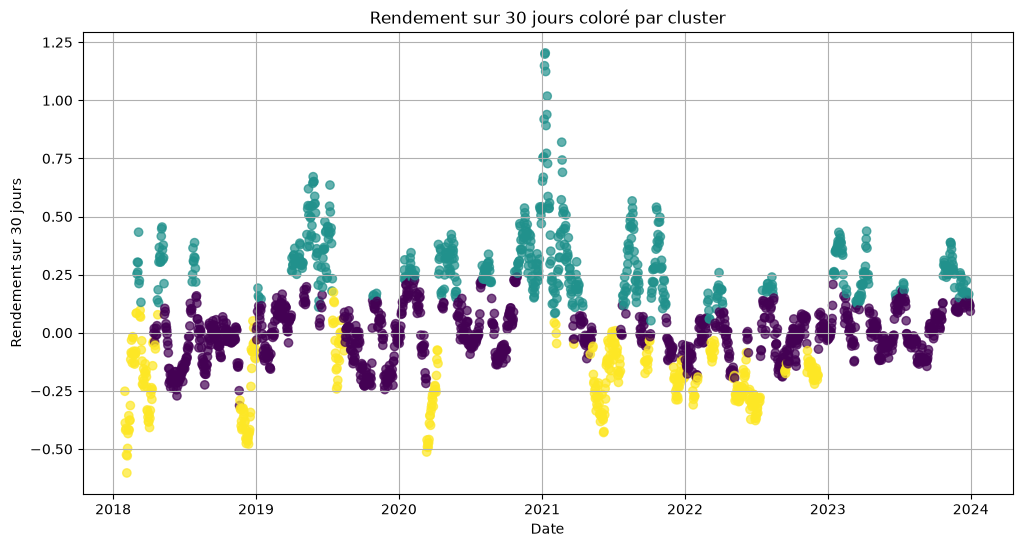

In [45]:
# Visualisation du rendement 30 jours avec coloration par cluster
plt.scatter(
    df.index,
    df["return_30d"],
    c=df["cluster"],
    cmap="viridis",
    alpha=0.7
)

plt.title("Rendement sur 30 jours coloré par cluster")
plt.xlabel("Date")
plt.ylabel("Rendement sur 30 jours")
plt.grid(True)
plt.show()

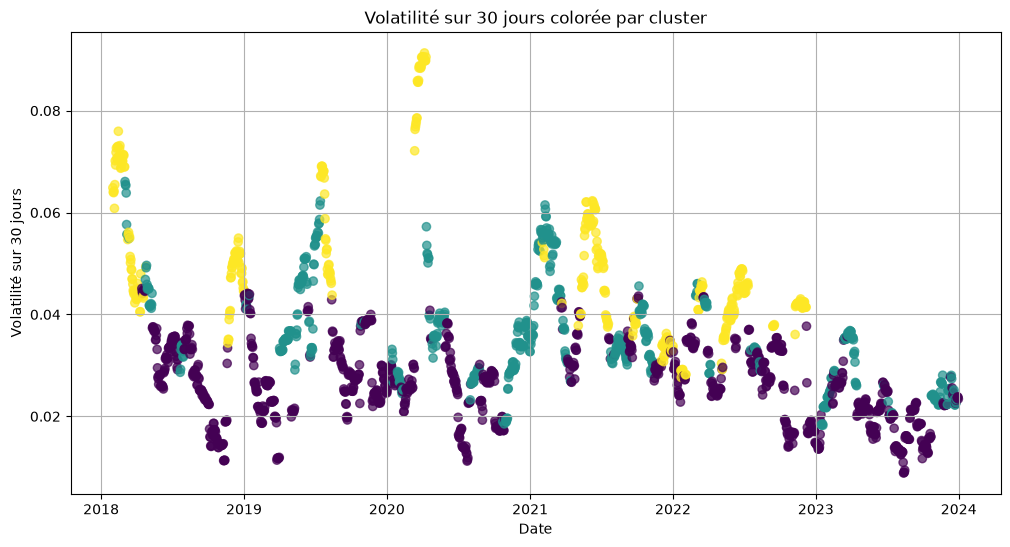

In [46]:
# Visualisation de la volatilité 30 jours avec coloration par cluster
plt.scatter(
    df.index,
    df["volatility_30d"],
    c=df["cluster"],
    cmap="viridis",
    alpha=0.7
)

plt.title("Volatilité sur 30 jours colorée par cluster")
plt.xlabel("Date")
plt.ylabel("Volatilité sur 30 jours")
plt.grid(True)
plt.show()

In [47]:
# Bonus : mesurer la persistance des clusters dans le temps
changes = (df["cluster"] != df["cluster"].shift()).sum() - 1
runs = df["cluster"].ne(df["cluster"].shift()).cumsum()
run_lengths = df.groupby(runs).size()

print("Nombre de changements de cluster :", changes, "sur", len(df), "jours")
print("Durée moyenne d'une séquence dans le même cluster : {:.1f} jours".format(run_lengths.mean()))
print("Séquence la plus longue : {} jours".format(run_lengths.max()))

Nombre de changements de cluster : 158 sur 2161 jours
Durée moyenne d'une séquence dans le même cluster : 13.6 jours
Séquence la plus longue : 112 jours


## Question 12

 **Réponses** (à adapter à tes graphiques)

**1. Les clusters apparaissent-ils par périodes continues ou de manière très dispersée ?**
Majoritairement par **périodes continues** : on observe de longues séquences de la même couleur (plusieurs semaines ou mois), ce que confirme la durée moyenne des séquences du bonus. C'est logique, car `return_30d`, `volatility_30d` et `momentum_30d` sont calculées sur des **fenêtres glissantes de 30 jours** qui se recouvrent à 29/30 d'un jour à l'autre : ces variables évoluent lentement. Il y a cependant des **alternances rapides** aux frontières entre régimes, et `volume_change` (variable journalière très bruitée) peut faire basculer des journées isolées dans un autre cluster.

**2. Observe-t-on des changements de cluster pendant les périodes de forte volatilité ?**
Oui. Les grandes crises font **basculer** le marché vers le cluster le plus volatil : début 2018, mars-avril 2020, mai-juillet 2021, mai-juin et novembre 2022. Pendant ces phases, les changements sont aussi plus **fréquents**, car le marché passe brusquement d'un comportement à l'autre (krach puis rebond violent). Le basculement apparaît avec un **léger retard** sur l'événement, le temps que la fenêtre de 30 jours intègre les journées extrêmes.

**3. Certains clusters semblent-ils associés à des phases de hausse ou de baisse du Bitcoin ?**
Oui : le cluster « haussier » couvre surtout la grande hausse de **fin 2020 - début 2021** (de 10 000 $ à plus de 60 000 $) et des épisodes de 2019 et 2023 ; le cluster « volatil » est surtout associé aux **chutes** (2018, mars 2020, 2022). Le cluster « calme » domine les phases de stagnation (fin 2018 - 2019, 2020 avant la hausse, 2023). On remarque aussi que **le même régime peut apparaître à des niveaux de prix très différents** : c'est l'intérêt de features relatives (rendements, volatilité) plutôt que du prix. Le momentum en dollars, lui, rend les clusters partiellement liés au niveau du prix.

**4. Pourquoi la visualisation temporelle est-elle importante pour interpréter des clusters financiers ?**
- Elle **valide** l'interprétation : si un cluster nommé « crise » correspond bien aux krachs connus (mars 2020, FTX), le découpage a un sens financier. S'il est éparpillé au hasard dans le temps, c'est probablement du bruit.
- Elle montre la **persistance** des régimes : un vrai régime de marché dure. Un cluster qui change tous les jours n'est pas un régime exploitable.
- Elle révèle des **biais** : un cluster qui ne regroupe qu'une seule année reflète peut-être le niveau du prix (via le momentum en dollars) plutôt qu'un comportement.
- Le clustering a **ignoré l'ordre du temps** (chaque journée est un point indépendant) : le fait que des régimes continus apparaissent malgré tout est un résultat en soi, qu'on ne voit qu'en replaçant les labels sur l'axe du temps.

---
# PARTIE 9 — DBSCAN

 **Concept** : DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) définit les clusters comme des **zones denses**.
- Un point est **central** (*core point*) s'il a au moins `min_samples` voisins dans un rayon `eps`.
- Les points centraux voisins sont reliés et forment un cluster ; les points proches d'un point central sans être centraux eux-mêmes sont des points de **bordure**.
- Les points qui ne sont ni centraux ni proches d'un point central sont du **bruit** : label **−1**.

Avantages : pas besoin de choisir le nombre de clusters, formes quelconques, détection du bruit. Inconvénient : tout dépend de `eps` (et de `min_samples`).

In [48]:
# TODO : modèle DBSCAN
dbscan = DBSCAN(
    eps=0.5,
    min_samples=10
)

In [49]:
# TODO : entraîner DBSCAN sur X_scaled et récupérer les labels
dbscan_labels = dbscan.fit_predict(X_scaled)

In [50]:
# TODO : ajouter les labels au dataframe
df["dbscan_cluster"] = dbscan_labels

In [51]:
# TODO : nombre d'observations par label DBSCAN
df["dbscan_cluster"].value_counts().sort_index()

dbscan_cluster
-1     462
 0      17
 1    1651
 2      21
 3      10
Name: count, dtype: int64

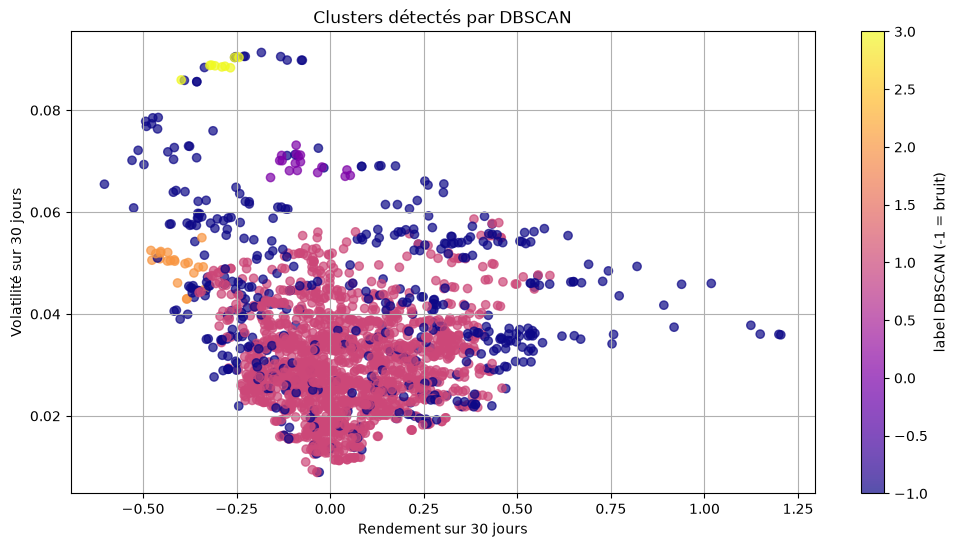

In [52]:
# Visualisation des clusters DBSCAN
plt.scatter(
    df["return_30d"],
    df["volatility_30d"],
    c=df["dbscan_cluster"],
    cmap="plasma",
    alpha=0.7
)

plt.title("Clusters détectés par DBSCAN")
plt.xlabel("Rendement sur 30 jours")
plt.ylabel("Volatilité sur 30 jours")
plt.grid(True)
plt.colorbar(label="label DBSCAN (-1 = bruit)")
plt.show()

## Questions

 **Réponses** (à adapter à ton `value_counts`)

**1. Combien de clusters DBSCAN détecte-t-il ?**
Compte les labels **différents de −1** dans le `value_counts`. Avec `eps = 0.5` et `min_samples = 10` en 4 dimensions normalisées, DBSCAN trouve en général **un grand cluster principal** (le noyau dense des journées « normales ») et éventuellement **un ou quelques petits clusters** (des grappes de journées consécutives d'une même période extrême). C'est très différent de K-Means : DBSCAN ne découpe pas le noyau dense en morceaux, car il est **connexe**.

**2. Observe-t-on des points avec le label −1 ?**
Oui, généralement une part non négligeable des journées (de quelques pourcents à plus de 20 % selon les paramètres). Sur le graphique, ce sont surtout les points des **bords** du nuage : rendements sur 30 jours extrêmes, très forte volatilité, ou journées avec une variation de volume exceptionnelle (qui peuvent sembler au milieu du nuage sur le graphique 2D, car elles sont isolées sur l'axe du volume, non affiché).

**3. Que représente le label −1 ?**
Le **bruit** : des points qui ne sont dans **aucune zone dense**, c'est-à-dire qui ont moins de `min_samples` voisins dans un rayon `eps` et qui ne sont proches d'aucun point central. DBSCAN refuse de les affecter à un cluster. Ce n'est **pas** un cluster « des points bizarres » : ces points n'ont rien en commun, à part d'être isolés.

**4. Pourquoi DBSCAN peut-il identifier certains points comme atypiques ?**
Parce que sa définition d'un cluster repose sur la **densité locale**, et non sur la distance à un centre. Un point situé dans une zone vide de l'espace ne remplit pas le critère de densité : DBSCAN n'est pas obligé de le rattacher à un groupe. K-Means, au contraire, affecte **chaque** point au centre le plus proche, même s'il est très loin de tout. DBSCAN est donc naturellement un outil de **détection d'anomalies** : les journées de krach, les bulles extrêmes ou les pics de volume ressortent comme des points isolés.

---
# PARTIE 10 — Sensibilité du paramètre eps

In [53]:
# TODO : tester plusieurs valeurs de eps
eps_values = [0.2, 0.3, 0.5, 0.7, 1.0]

for eps in eps_values:

    model = DBSCAN(
        eps=eps,
        min_samples=10
    )

    labels_eps = model.fit_predict(X_scaled)

    n_clusters = len(set(labels_eps)) - (1 if -1 in labels_eps else 0)

    n_noise = np.sum(labels_eps == -1)

    print("eps =", eps,
          "| clusters =", n_clusters,
          "| bruit =", n_noise,
          f"({n_noise / len(labels_eps):.0%})")

eps = 0.2 | clusters = 8 | bruit = 1932 (89%)
eps = 0.3 | clusters = 3 | bruit = 1308 (61%)
eps = 0.5 | clusters = 4 | bruit = 462 (21%)
eps = 0.7 | clusters = 3 | bruit = 196 (9%)
eps = 1.0 | clusters = 1 | bruit = 49 (2%)


## Questions

 **Réponses**

**1. Que se passe-t-il lorsque eps est très petit ?**
Le voisinage de chaque point est minuscule : peu de points ont 10 voisins dans un si petit rayon. Une **grande partie** des journées est classée en **bruit** (souvent la majorité avec `eps = 0.2`), et les zones denses restantes sont **fragmentées** en plusieurs petits clusters. Le résultat décrit surtout la structure très locale (des grappes de jours consécutifs) et pas les grands régimes.

**2. Que se passe-t-il lorsque eps est plus grand ?**
Les voisinages s'agrandissent : de plus en plus de points deviennent centraux et les zones denses **se rejoignent**. Le bruit diminue fortement et les clusters **fusionnent**, jusqu'à obtenir **un seul grand cluster** contenant presque toutes les journées (avec `eps = 1.0`, il ne reste en général que quelques points extrêmes en bruit). On perd alors toute structure.

**3. Pourquoi le choix de eps est-il délicat ?**
- Le résultat change **brutalement** avec eps : on passe de « tout est bruit » à « tout est dans un seul cluster » sur une plage étroite de valeurs.
- Il n'y a pas de **vraie réponse** pour valider le choix, et pas de règle universelle : la bonne valeur dépend de l'échelle et de la densité des données, du nombre de dimensions (en 4D, les distances sont plus grandes qu'en 2D) et de `min_samples`.
- eps est un rayon dans l'espace **normalisé**, donc difficile à interpréter financièrement.

Une méthode courante pour guider le choix est le **graphe des k-distances** (bonus ci-dessous) : on trace, pour chaque point, la distance à son k-ième plus proche voisin, triée par ordre croissant ; le « coude » de cette courbe donne une valeur raisonnable d'eps.

**4. Pourquoi DBSCAN peut-il être difficile à utiliser lorsque les densités varient fortement ?**
Parce qu'il utilise **un seul eps pour tout l'espace**, donc un **seul seuil de densité**. Or ici, le noyau des journées normales est très dense et les régimes de crise sont naturellement **peu denses** (rares, étalés). Un eps adapté au noyau dense classe les crises en bruit ; un eps assez grand pour regrouper les crises fusionne tout le noyau. Il n'existe pas de valeur qui convienne aux deux zones à la fois. C'est la limite principale de DBSCAN, qui motive OPTICS et HDBSCAN (partie 13).

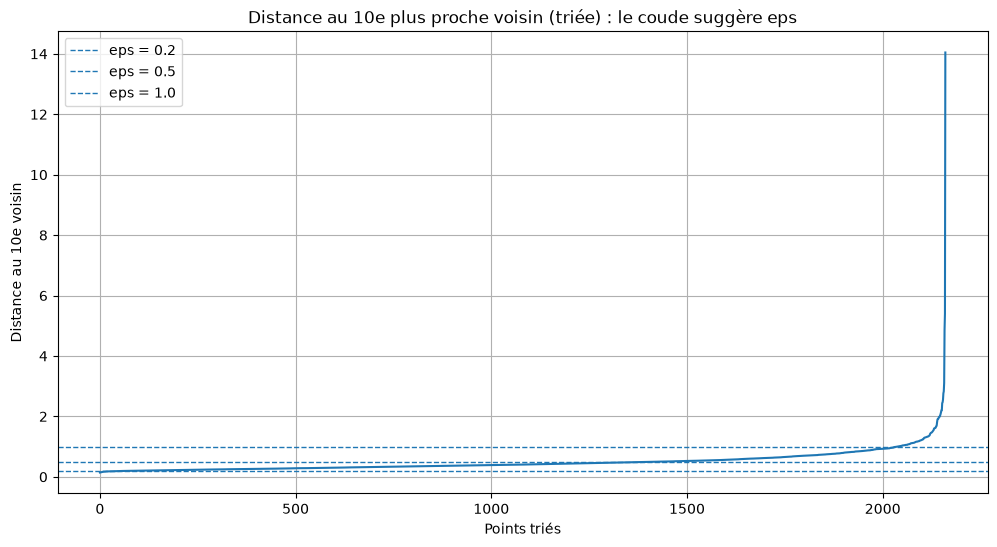

Part des points dont le 10e voisin est à moins de eps :
  eps = 0.2 : 4%
  eps = 0.3 : 27%
  eps = 0.5 : 66%
  eps = 0.7 : 83%
  eps = 1.0 : 94%


In [54]:
# Bonus : graphe des k-distances pour guider le choix de eps (k = min_samples)
from sklearn.neighbors import NearestNeighbors

nn = NearestNeighbors(n_neighbors=10).fit(X_scaled)
distances, _ = nn.kneighbors(X_scaled)
k_dist = np.sort(distances[:, -1])

plt.plot(k_dist)
for eps in [0.2, 0.5, 1.0]:
    plt.axhline(eps, ls="--", lw=1, label=f"eps = {eps}")
plt.title("Distance au 10e plus proche voisin (triée) : le coude suggère eps")
plt.xlabel("Points triés"); plt.ylabel("Distance au 10e voisin")
plt.legend(); plt.grid(True); plt.show()

print("Part des points dont le 10e voisin est à moins de eps :")
for eps in eps_values:
    print(f"  eps = {eps} : {np.mean(k_dist <= eps):.0%}")

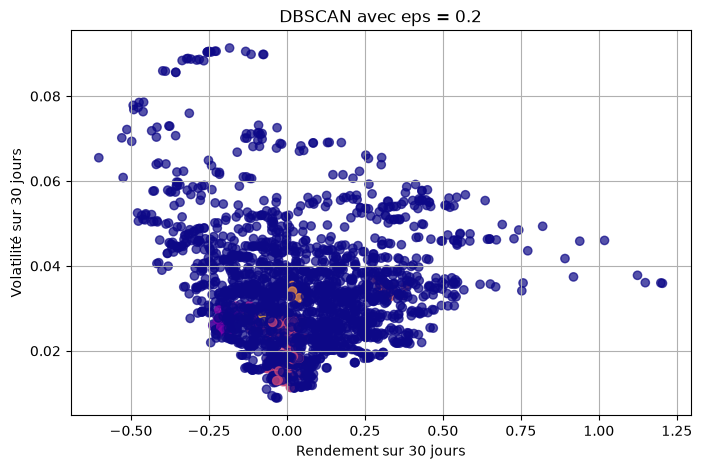

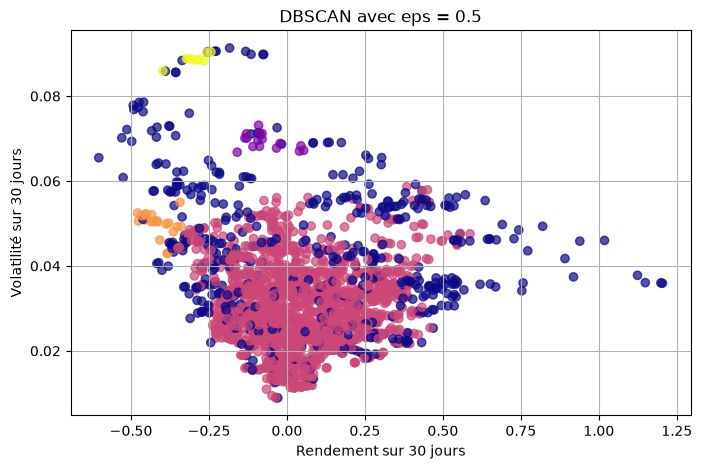

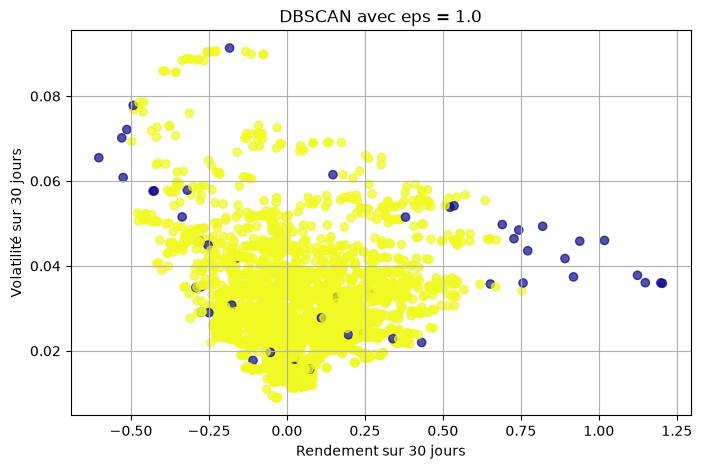

In [55]:
# Visualiser plusieurs valeurs de eps
eps_values = [0.2, 0.5, 1.0]

for eps in eps_values:

    model = DBSCAN(
        eps=eps,
        min_samples=10
    )

    labels_eps = model.fit_predict(X_scaled)

    plt.figure(figsize=(8, 5))

    plt.scatter(
        df["return_30d"],
        df["volatility_30d"],
        c=labels_eps,
        cmap="plasma",
        alpha=0.7
    )

    plt.title("DBSCAN avec eps = " + str(eps))
    plt.xlabel("Rendement sur 30 jours")
    plt.ylabel("Volatilité sur 30 jours")
    plt.grid(True)
    plt.show()

## Questions

 **Réponses**

**1. Les visualisations changent-elles fortement selon eps ?**
Oui, radicalement. Avec `eps = 0.2`, le graphique est dominé par la couleur du **bruit** avec quelques petits îlots colorés ; avec `eps = 0.5`, un grand cluster principal apparaît, entouré de points de bruit sur les bords ; avec `eps = 1.0`, presque tout est d'une **seule couleur**. Les mêmes données donnent trois « réalités » différentes, uniquement à cause d'un paramètre.

**2. Quelle valeur semble produire le résultat le plus interprétable ?**
En général la valeur **intermédiaire (0.5)** : elle sépare un **noyau de journées normales** d'un ensemble de **journées atypiques** (crises, bulles, pics de volume), ce qui correspond à une lecture financière claire, « marché normal / événements exceptionnels ». `0.2` fragmente trop et `1.0` ne distingue plus rien. Le choix dépend aussi de l'objectif : pour détecter des anomalies, un eps un peu plus petit (plus de bruit) peut être préférable.

**3. Pourquoi « interprétable » ne signifie-t-il pas forcément « vrai » ?**
- On a **choisi** la valeur d'eps qui donnait le résultat le plus conforme à nos attentes : c'est un **biais de confirmation**. Un découpage qui « raconte une belle histoire » n'est pas pour autant la structure réelle des données.
- Il n'existe **pas de vérité terrain** en non supervisé : aucun « vrai » nombre de régimes de marché auquel se comparer. Plusieurs organisations des données peuvent être valables à différentes échelles.
- Le résultat dépend aussi des features, de la normalisation et de `min_samples` : un autre ensemble de choix aurait pu produire un autre découpage, tout aussi « interprétable ».
- Notre cerveau trouve facilement des motifs, même dans du bruit.

**4. Quel lien avec la limite de DBSCAN vue dans le CM4 ?**
C'est l'illustration directe de sa limite principale : **un seul niveau de densité global** (un eps unique). La forte sensibilité à eps vient du fait que les données ont des **densités très différentes** selon les régions (noyau dense des journées calmes, zones éparses des crises) : chaque valeur d'eps n'est adaptée qu'à l'une de ces densités.

---
# PARTIE 11 — Comparaison K-Means vs DBSCAN

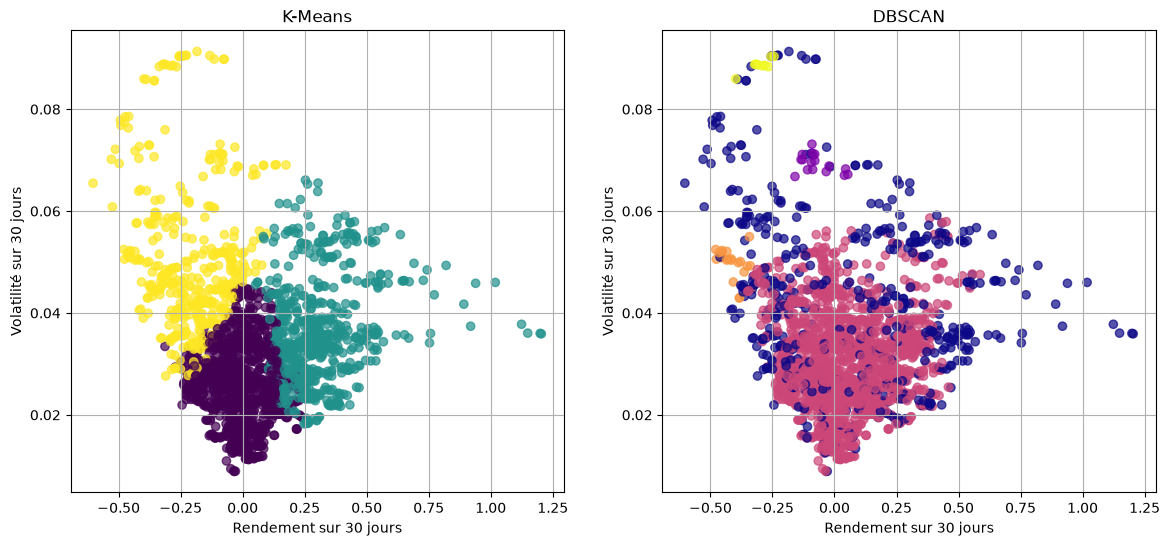

In [56]:
# Comparaison visuelle K-Means vs DBSCAN
plt.figure(figsize=(14, 6))

# ============================================================
# K-Means
# ============================================================
plt.subplot(1, 2, 1)
plt.scatter(
    df["return_30d"],
    df["volatility_30d"],
    c=df["cluster"],
    cmap="viridis",
    alpha=0.7
)
plt.title("K-Means")
plt.xlabel("Rendement sur 30 jours")
plt.ylabel("Volatilité sur 30 jours")
plt.grid(True)

# ============================================================
# DBSCAN
# ============================================================
plt.subplot(1, 2, 2)
plt.scatter(
    df["return_30d"],
    df["volatility_30d"],
    c=df["dbscan_cluster"],
    cmap="plasma",
    alpha=0.7
)
plt.title("DBSCAN")
plt.xlabel("Rendement sur 30 jours")
plt.ylabel("Volatilité sur 30 jours")
plt.grid(True)

plt.show()

In [57]:
# Bonus : tableau croisé K-Means x DBSCAN (où vont les journées de chaque cluster K-Means ?)
pd.crosstab(df["cluster_name"], df["dbscan_cluster"], margins=True)

dbscan_cluster,-1,0,1,2,3,All
cluster_name,,,,,,
Marché calme,72,0,1086,0,0,1158
Marché haussier,213,0,384,0,0,597
Marché volatil (crise),177,17,181,21,10,406
All,462,17,1651,21,10,2161


## Questions

 **Réponses** (à adapter à tes graphiques et au tableau croisé)

**1. Quelle méthode semble produire les clusters les plus compacts ?**
**K-Means**, par construction : il minimise directement la dispersion autour des centres (l'inertie) et produit des groupes **convexes et équilibrés**. Les clusters de DBSCAN suivent la forme des zones denses : le grand cluster principal peut être **étendu et de forme irrégulière**, mais il est cohérent en densité.

**2. Quelle méthode semble mieux gérer les points atypiques ?**
**DBSCAN** : il les isole dans le **bruit** (label −1) au lieu de les forcer dans un groupe. K-Means doit rattacher chaque journée extrême à un cluster : soit il crée un cluster dédié aux extrêmes (très étalé), soit les extrêmes **déplacent les centroïdes** (une moyenne est sensible aux valeurs aberrantes) et déforment les clusters normaux.

**3. DBSCAN détecte-t-il des structures que K-Means ne voit pas ?**
Oui, sur deux points :
- il distingue les **journées atypiques** (bruit), une notion qui n'existe pas dans K-Means ; le tableau croisé montre en général que ce bruit provient surtout du cluster K-Means « volatil (crise) » et du cluster « haussier », mais aussi de journées du cluster « calme » isolées par une variation de volume exceptionnelle ;
- il peut trouver des petits groupes **denses** de forme quelconque (par exemple une grappe de journées consécutives d'une même crise), là où K-Means ne voit que des partitions convexes.

À l'inverse, K-Means **découpe** le noyau dense en sous-régimes (calme / haussier), alors que DBSCAN le voit comme un seul bloc **connexe**, car il n'y a pas de zone vide pour le séparer.

**4. Pourquoi deux méthodes différentes peuvent-elles proposer des organisations différentes des données ?**
Parce qu'elles ne cherchent **pas la même chose** : elles reposent sur deux définitions différentes d'un « cluster ».
- K-Means : un groupe de points **proches d'un centre commun** ; il impose K groupes, partitionne tout l'espace et privilégie des formes rondes.
- DBSCAN : une **région dense connexe** ; il trouve lui-même le nombre de groupes, accepte des formes quelconques et laisse des points sans groupe.

Sur un nuage **continu** comme celui-ci, sans séparation nette, chaque définition « voit » une organisation différente, et aucune n'est la seule correcte.

**5. Peut-on dire qu'une méthode est toujours meilleure que l'autre ?**
Non. Chaque méthode est adaptée à un **type de structure** et à un **objectif** :
- K-Means est préférable pour **segmenter** toutes les journées en quelques régimes comparables et interprétables par un profil moyen (résumer, étiqueter chaque jour) ;
- DBSCAN est préférable pour **détecter des anomalies** et des groupes de forme irrégulière, quand on ne connaît pas le nombre de groupes.

Le choix dépend des données (formes, densités, bruit) et de la question posée. En pratique, on compare plusieurs méthodes et on garde celle dont les résultats sont **stables** et **utiles** pour le métier.

In [58]:
# TODO : nombre de clusters détectés par chaque méthode (le label -1 de DBSCAN est le bruit)
n_clusters_kmeans = len(np.unique(df["cluster"]))

n_clusters_dbscan = len(set(df["dbscan_cluster"]) - {-1})

print("Nombre de clusters K-Means :", n_clusters_kmeans)

print("Nombre de clusters DBSCAN :", n_clusters_dbscan)

Nombre de clusters K-Means : 3
Nombre de clusters DBSCAN : 4


In [59]:
# TODO : pourcentage de bruit DBSCAN
noise_ratio = (df["dbscan_cluster"] == -1).mean()

print("Pourcentage de bruit :", round(noise_ratio * 100, 2), "%")

Pourcentage de bruit : 21.38 %


In [60]:
# Bonus : quand se situent les journées de bruit ? Les 10 plus extrêmes et leur répartition par année
noise = df[df["dbscan_cluster"] == -1]
print("Journées de bruit par année :")
print(noise.index.year.value_counts().sort_index().to_string())

print("\nExemples de journées de bruit (les plus volatiles) :")
noise.sort_values("volatility_30d", ascending=False)[["Close", "return_30d", "volatility_30d", "volume_change"]].head(10)

Journées de bruit par année :
Date
2018     57
2019     32
2020     59
2021    169
2022     79
2023     66

Exemples de journées de bruit (les plus volatiles) :


Price,Close,return_30d,volatility_30d,volume_change
Date,,,,
2020-04-06,7271.781250,-0.183859,0.091330,0.589165
2020-04-03,6733.387207,-0.230931,0.090578,-0.182208
2020-04-02,6793.624512,-0.226924,0.090573,0.181285
2020-04-10,6865.493164,-0.132206,0.090525,0.252985
2020-03-30,6429.841797,-0.252301,0.090499,0.307608
2020-04-01,6606.776367,-0.255127,0.090373,0.230582
2020-04-07,7176.414551,-0.114910,0.089843,-0.056580
2020-04-09,7302.089355,-0.076822,0.089820,-0.073160
2020-04-08,7334.098633,-0.074403,0.089815,-0.150988


## Questions

 **Réponses**

**1. Pourquoi DBSCAN peut-il considérer certaines observations comme du bruit ?**
Parce qu'elles se trouvent dans des **zones de faible densité** : elles ont moins de `min_samples` (10) voisins dans un rayon `eps` et ne sont proches d'aucun point central. DBSCAN considère qu'elles n'appartiennent à **aucune structure** collective et ne les force pas dans un groupe.

**2. En finance, à quoi pourraient correspondre ces points atypiques ?**
- des **krachs** et paniques : mars 2020 (Covid), juin 2022 (Terra/Luna, Celsius), novembre 2022 (FTX) ;
- des phases d'**euphorie spéculative** extrême : la bulle de fin 2020 - début 2021, avec des hausses de plus de 50 % en un mois ;
- des **pics d'activité** anormaux : journées où le volume explose (liquidations massives, annonces réglementaires, anomalie de données d'une plateforme) ;
- éventuellement des **erreurs de données**, qu'il faut toujours vérifier.

**3. Pourquoi certaines périodes extrêmes peuvent-elles être isolées du reste des données ?**
Parce qu'elles sont **rares** et **extrêmes** : quelques semaines de crise sur 6 ans, avec des valeurs de volatilité ou de rendement jamais atteintes le reste du temps. Il n'y a pas assez de journées semblables autour d'elles pour former une zone dense. De plus, chaque crise est **unique** (le krach de mars 2020 ne ressemble pas exactement à celui de FTX) : même entre elles, ces journées ne forment pas un groupe compact. Elles se retrouvent loin du noyau et loin les unes des autres.

**4. Pourquoi cette propriété peut-elle être utile pour la détection d'anomalies ?**
DBSCAN fournit une détection d'anomalies **non supervisée** : sans avoir besoin d'exemples de crises étiquetées, il signale automatiquement les observations qui **ne ressemblent à aucun comportement habituel**. En finance, cela peut servir à :
- déclencher des **alertes de risque** (le marché sort de son régime normal) ;
- détecter des **fraudes** ou manipulations (transactions anormales) ;
- **nettoyer** les données (erreurs, valeurs aberrantes) avant d'entraîner d'autres modèles ;
- isoler les événements extrêmes pour les étudier séparément (stress tests).

La même idée s'applique en cybersécurité (détection d'intrusions, logs anormaux), en industrie (pannes) ou en santé.

---
# PARTIE 12 — Analyse critique des méthodes

Point fondamental : **un cluster n'est pas une vérité absolue**, mais une organisation possible des données.

In [61]:
# TODO : clustering SANS normalisation
kmeans_no_scaling = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

labels_no_scaling = kmeans_no_scaling.fit_predict(X)

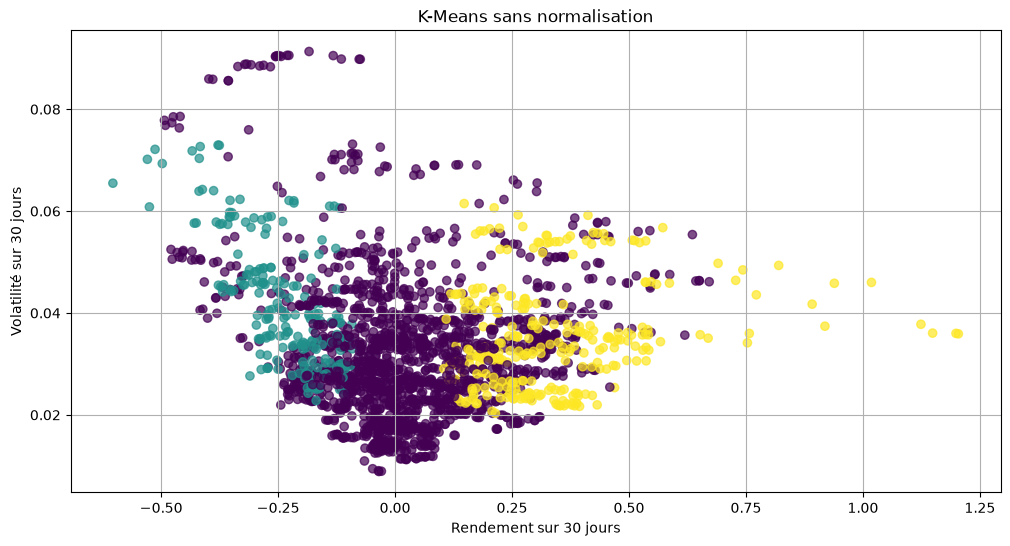

In [62]:
# Visualisation sans normalisation
plt.scatter(
    df["return_30d"],
    df["volatility_30d"],
    c=labels_no_scaling,
    cmap="viridis",
    alpha=0.7
)

plt.title("K-Means sans normalisation")
plt.xlabel("Rendement sur 30 jours")
plt.ylabel("Volatilité sur 30 jours")
plt.grid(True)
plt.show()

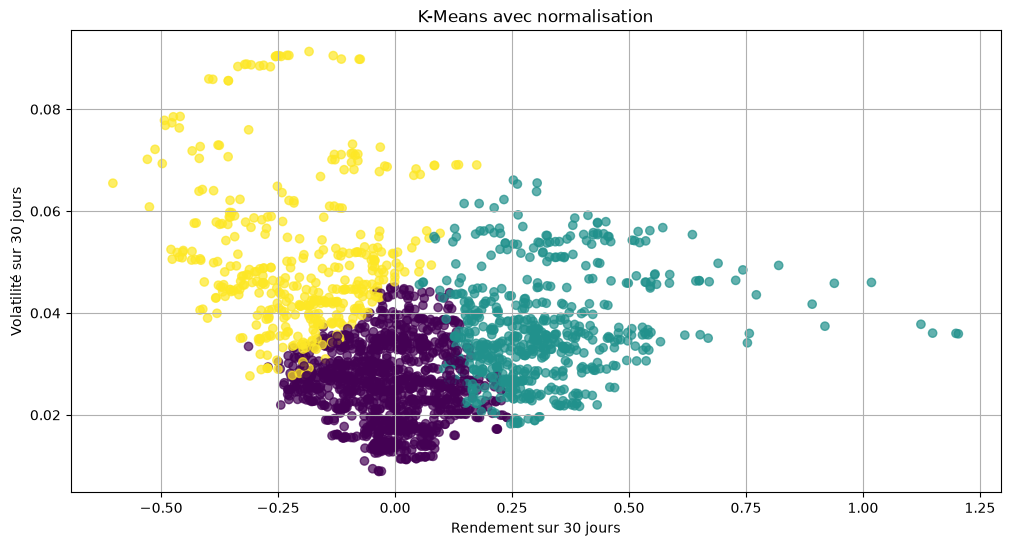

In [63]:
# Visualisation avec normalisation
plt.scatter(
    df["return_30d"],
    df["volatility_30d"],
    c=df["cluster"],
    cmap="viridis",
    alpha=0.7
)

plt.title("K-Means avec normalisation")
plt.xlabel("Rendement sur 30 jours")
plt.ylabel("Volatilité sur 30 jours")
plt.grid(True)
plt.show()

Momentum moyen par cluster SANS normalisation (en $) :
      mean      min      max  count
0     70.0  -5104.0   4936.0   1673
1 -10328.0 -25243.0  -5136.0    200
2   9840.0   4975.0  25274.0    288


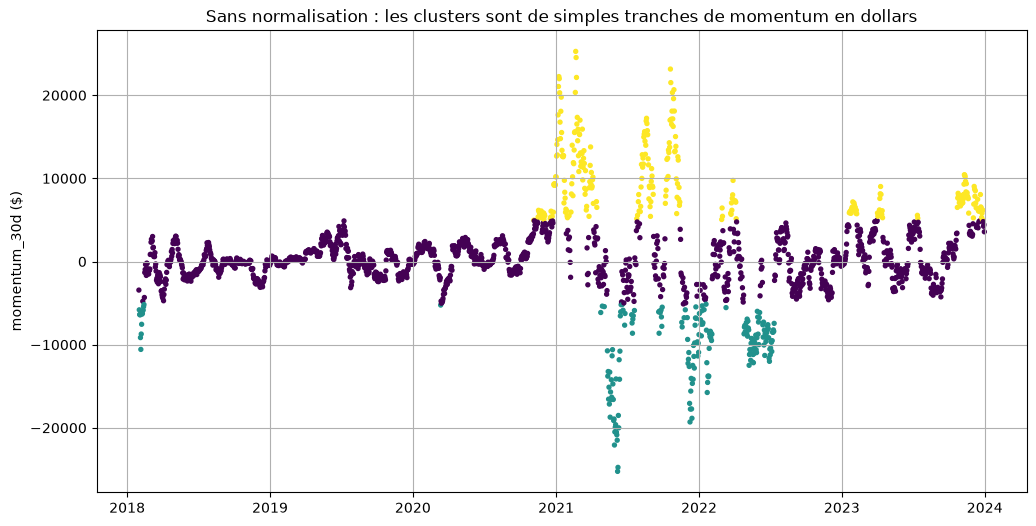

Accord entre les deux clusterings (Adjusted Rand Index, 1 = identiques, 0 = hasard) : 0.292


In [64]:
# Bonus : preuve que le momentum (en dollars) dicte seul le clustering sans normalisation
print("Momentum moyen par cluster SANS normalisation (en $) :")
print(df.groupby(labels_no_scaling)["momentum_30d"].agg(["mean", "min", "max", "count"]).round(0))

plt.scatter(df.index, df["momentum_30d"], c=labels_no_scaling, cmap="viridis", s=8)
plt.title("Sans normalisation : les clusters sont de simples tranches de momentum en dollars")
plt.ylabel("momentum_30d ($)"); plt.grid(True); plt.show()

from sklearn.metrics import adjusted_rand_score
print("Accord entre les deux clusterings (Adjusted Rand Index, 1 = identiques, 0 = hasard) :",
      round(adjusted_rand_score(df["cluster"], labels_no_scaling), 3))

## Questions

 **Réponses**

**1. Les clusters changent-ils fortement lorsque la normalisation est supprimée ?**
Oui, complètement. Sans normalisation, les couleurs ne suivent plus la volatilité ni le rendement en pourcentage : sur le graphique (return_30d, volatility_30d), les clusters semblent **mélangés** et sans logique apparente. L'indice de Rand ajusté entre les deux découpages est faible : les deux clusterings sont très différents.

**2. Pourquoi une seule variable peut-elle dominer les distances sans normalisation ?**
Parce que la distance euclidienne additionne les écarts **au carré** de chaque variable dans **leur unité d'origine**. `momentum_30d` est en dollars, avec des écarts de l'ordre de plusieurs milliers ; les autres variables ont des écarts de l'ordre de 0,01 à 1. Les carrés des écarts de momentum (≈ $10^6$ à $10^8$) écrasent ceux des autres variables (≈ $10^{-4}$ à 1). K-Means, qui minimise ces distances, ne « voit » donc que le momentum : le bonus montre que les trois clusters sont simplement trois **tranches** de momentum (forte baisse en $, stagnation, forte hausse en $). Et comme le momentum en dollars est grand surtout quand le prix est élevé, les clusters « extrêmes » sont concentrés en 2021-2022.

**3. Pourquoi cela montre-t-il que le clustering dépend fortement de la représentation des données ?**
Avec **exactement les mêmes données** et le **même algorithme**, un simple changement d'échelle des variables donne un résultat totalement différent. Le clustering ne découvre pas une structure « absolue » : il découvre la structure **de la représentation qu'on lui donne** (features choisies, unités, normalisation, distance, poids implicites). Exprimer le momentum en milliers de dollars ou en centimes changerait encore le résultat, sans que la réalité du marché ait changé. Même avec normalisation, le choix est implicite : la normalisation donne un poids égal à chaque variable, et `return_30d` et `momentum_30d`, presque redondantes, comptent pratiquement double.

**4. Pourquoi faut-il être très prudent avant d'interpréter des clusters ?**
- Un algorithme de clustering trouve **toujours** des clusters (K-Means renvoie K groupes même dans des données sans aucune structure) : leur existence ne prouve rien.
- Le résultat dépend de nombreux choix **arbitraires** : features, normalisation, distance, K ou eps, initialisation, algorithme. Un autre choix peut donner une autre « vérité ».
- Il n'y a pas de **vérité terrain** pour valider, et les critères internes (silhouette, inertie) reposent eux-mêmes sur des hypothèses.
- On risque de **projeter** nos attentes (biais de confirmation) en nommant les clusters.

Il faut donc vérifier la **stabilité** des clusters (changer la graine, la période, les paramètres), leur **cohérence** avec des connaissances métier (visualisation temporelle) et les considérer comme une **aide à l'exploration**, pas comme une conclusion.

---
# PARTIE 13 — Ouverture : OPTICS et HDBSCAN

 **Concept**
- **OPTICS** (*Ordering Points To Identify the Clustering Structure*) ne fixe pas un eps unique : il ordonne les points selon leur **distance d'accessibilité** et produit un graphe (le *reachability plot*) où les clusters apparaissent comme des **vallées**, à toutes les échelles de densité à la fois.
- **HDBSCAN** (*Hierarchical DBSCAN*) construit la **hiérarchie** de tous les clusters obtenus pour toutes les valeurs d'eps, puis garde les clusters les plus **stables** (ceux qui persistent sur la plus grande plage de densités). Il n'a besoin que d'une taille minimale de cluster.

Les deux sont disponibles dans scikit-learn (`sklearn.cluster.OPTICS` et `sklearn.cluster.HDBSCAN`, depuis la version 1.3).

c:\Users\monka\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


HDBSCAN | clusters : 0 | bruit : 100%
-1    2161


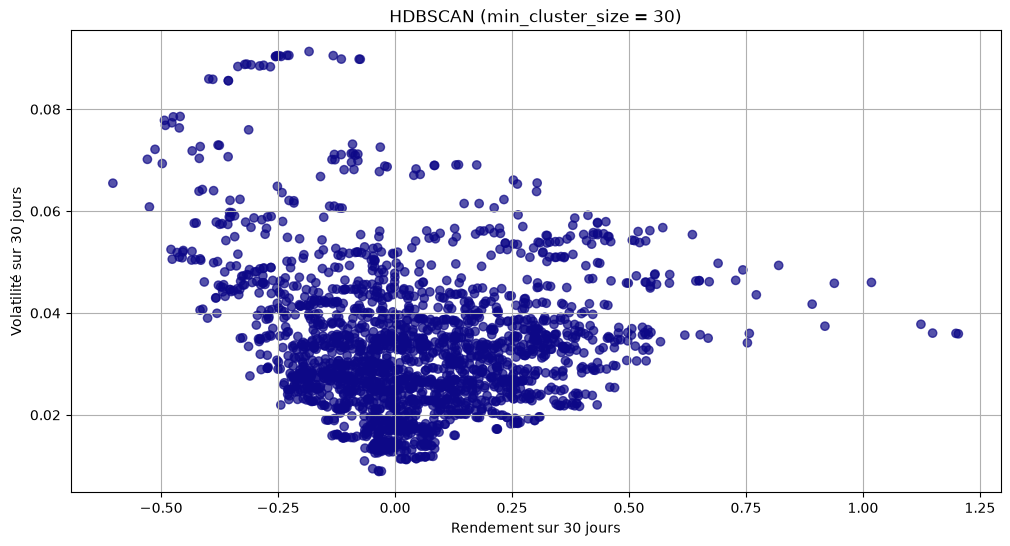

In [65]:
# Bonus : HDBSCAN sur les mêmes données (pas de eps à choisir)
try:
    from sklearn.cluster import HDBSCAN
    hdb = HDBSCAN(min_cluster_size=30, min_samples=10)
    hdb_labels = hdb.fit_predict(X_scaled)

    print("HDBSCAN | clusters :", len(set(hdb_labels) - {-1}),
          "| bruit :", f"{np.mean(hdb_labels == -1):.0%}")
    print(pd.Series(hdb_labels).value_counts().sort_index().to_string())

    plt.scatter(df["return_30d"], df["volatility_30d"], c=hdb_labels, cmap="plasma", alpha=0.7)
    plt.title("HDBSCAN (min_cluster_size = 30)")
    plt.xlabel("Rendement sur 30 jours"); plt.ylabel("Volatilité sur 30 jours"); plt.grid(True)
    plt.show()
except ImportError:
    print("HDBSCAN nécessite scikit-learn >= 1.3 : %pip install -U scikit-learn")

## Question 19

 **Réponses**

**1. Pourquoi un seul niveau de densité peut-il devenir insuffisant dans des données réelles ?**
Parce que les groupes réels n'ont pas tous la **même densité**. Un eps unique définit une seule notion de « zone dense » : s'il est adapté aux groupes denses, les groupes plus diffus sont classés en bruit ; s'il est adapté aux groupes diffus, les groupes denses voisins **fusionnent**. On l'a vu à la partie 10 : selon eps, on passe de « presque tout est bruit » à « un seul cluster », sans valeur qui capture à la fois le noyau dense et les régimes plus rares.

**2. Pourquoi certaines régions des données peuvent-elles être naturellement plus denses que d'autres ?**
Parce que certains comportements sont **beaucoup plus fréquents** que d'autres. En finance, le marché passe la majorité du temps dans un régime « normal » (volatilité modérée, rendements proches de 0) : des centaines de journées très semblables forment une zone dense. Les crises et les bulles sont **rares** (quelques semaines sur des années) et **plus variées** : leurs journées sont peu nombreuses et dispersées. C'est la conséquence des **queues épaisses** et du **clustering de volatilité** vus aux TP2 et TP3. Le même phénomène existe ailleurs : trafic réseau normal contre attaques, transactions courantes contre fraudes.

**3. Pourquoi des méthodes comme OPTICS ou HDBSCAN peuvent-elles être utiles ?**
- Elles **s'adaptent à des densités variables** : elles explorent toutes les échelles de densité au lieu d'en imposer une.
- Elles suppriment (ou réduisent fortement) le réglage délicat d'**eps**, remplacé par un paramètre plus intuitif (taille minimale d'un cluster).
- Elles gardent les avantages de DBSCAN : **nombre de clusters automatique**, formes quelconques, **détection du bruit**.
- HDBSCAN produit des clusters **stables** et fournit pour chaque point une probabilité d'appartenance ou un score d'anomalie, utile pour la détection d'anomalies.
- OPTICS fournit une visualisation de la structure **hiérarchique** (des clusters dans des clusters).

**4. Quel lien peut-on faire avec la limite principale de DBSCAN vue dans le CM4 ?**
La limite principale de DBSCAN est l'**utilisation d'un niveau de densité global** (un eps unique pour tout l'espace), qui le rend très sensible à eps et inadapté aux données de densités variables. OPTICS et HDBSCAN ont été conçus **précisément pour lever cette limite** : au lieu de choisir une densité, ils considèrent toutes les densités et en extraient les structures les plus pertinentes. Ce sont des **généralisations** de DBSCAN.

---
# Conclusion générale

- En **non supervisé**, il n'y a pas de cible : l'algorithme découvre une organisation des données à partir de leur **géométrie**.
- Le résultat dépend fortement de la **représentation** : choix des features, **normalisation** (sans elle, une seule variable en dollars dicte tout le clustering) et distance.
- **K-Means** partitionne toutes les journées en K groupes compacts autour de centroïdes ; il permet de dégager des régimes interprétables (calme, haussier, crise) qui apparaissent par **périodes continues** dans le temps, mais il impose le nombre et la forme des groupes.
- **DBSCAN** repose sur la densité : il ne force pas les points atypiques dans un groupe et détecte naturellement les **journées extrêmes** (krachs, bulles), mais il est très sensible à **eps**, car il utilise un seul niveau de densité. OPTICS et HDBSCAN répondent à cette limite.
- Les critères numériques (inertie, silhouette) aident à choisir les paramètres, mais l'**interprétation humaine et métier** reste indispensable.

> Le clustering est un **outil d'exploration intelligente** des données : il propose une organisation possible, pas une vérité.